# CWFS vignette analysis with new TIE and `danish`

Owner: **Bryce Kalmbach** ([@jbkalmbach](https://github.com/lsst-ts/ts_analysis_notebooks/issues/new?body=@jbkalmbach)) <br>
Last Verified to Run: 2024-04-15 <br>
Software Versions:
  - `ts_wep`: **v9.4.0**
  - `ts_imsim`: **v1.1.0**
  - `imSim`: **v2.0**
  - `danish`: **v0.5.0**
  - `lsst_distrib`: **w_2024_09**

## Notebook Objective:

In this notebook we will analyze the effects of vignetting on WEP Zernike Estimation and the convergence of the AOS closed loop. At the end we will establish a limit on the distance from the center of the LSSTCam focal plane for sources we will use in the WEP pipeline.

This notebook is an updated version that replaces Phosim with imSim and uses the refactored version of the `ts_wep` TIE wavefront estimation code found in `ts_wep` versions > 9.0. We also add in comparisons using the [`danish`](https://github.com/jmeyers314/danish) forward modeling code instead of the TIE on pairs of donuts. This requires `ts_wep` versions > 9.4.0.

## Contents

- [Logistics](#Logistics)
- [Progression of vignetting across the intra-focal detectors](#progression)
- [Zernike Estimation Performance with Vignetted Donuts](#zernike_estimation)
- [Closed loop results with vignetting](#closed_loop)
- [Calculate area of detector cut off](#detector)

## Logistics

This notebook is intended to be run on the USDF. The data sets are on the USDF at `/sdf/group/rubin/repo/aos_imsim/brycek/ts_analysis_notebooks_supporting_data/vignette_tests_new_TIE` and `/sdf/group/rubin/repo/aos_imsim/brycek/ts_analysis_notebooks_supporting_data/vignette_tests_danish`. 

The data was created by running the `ts_imsim` closed loop with a single extra-focal donut at the center of the extra-focal detector and a single intra-focal donut at a specified distance from the center of the focal plane ranging from 1.7297 degrees to 1.8351 degrees from the center of the LSSTCam focal plane. Background and atmospheric effects were included. Background subtraction was performed as part of the WEP pipeline. Catalogs used for each closed loop can be found in `/sdf/group/rubin/repo/aos_imsim/brycek/ts_analysis_notebooks_supporting_data/vignette_tests/catalogs`.

Example closed loop command: 
```bash
img_closed_loop.py --output closed_loop_tests/vignette_tests/single_donut_1.7297/ --iter_num 10 --config_pointer_file ts_imsim/policy/config/lsstCamLargePertPoin
ter.yaml --sky_file catalogs/vignette_tests/single_donut_1.7297.csv --clobber --num_proc 8 --wep_estimator tie
```

In [1]:
import os
import yaml
from lsst.daf.butler import Butler

from lsst.ts.wep.instrument import Instrument
from lsst.ts.wep.utils import runProgram, writePipetaskCmd, getConfigDir#, CamType
from lsst.ts.wep.task import DonutStamps
from lsst.ts.wep.task import CalcZernikesTask, CalcZernikesTaskConfig
from lsst.ts.wep.utils import convertZernikesToPsfWidth

import numpy as np
import matplotlib as mpl
mpl.rcParams['image.origin'] = 'lower'
import matplotlib.pyplot as plt

from IPython.display import Image
from scipy.ndimage import rotate
%matplotlib inline

## Progression of vignetting across the intra-focal detectors <a id='progression'></a>

In addition to the closed loop tests described above we performed a simulation with intra-focal donuts at a series of different distance from the center of the LSSTCam focal plane to show the degree of vignetting as you move towards the edge of the focal plane. This dataset is in the same folder as the closed loop tests in the `single_donut_all` directory. The images were ingested and the WEP pipeline run on the images shown below. In each image the center of the focal plane is in the direction of the top right corner of the detector and as sources are simulated closer to the bottom left corner the amount of vignetting increases.

In [2]:
# Repository with simulated data
supporting_data_folder = '/sdf/group/rubin/repo/aos_imsim/brycek/ts_analysis_notebooks_supporting_data/vignette_tests_new_TIE/'
butler_repo = os.path.join(supporting_data_folder, 'single_donut_all', 'imsimData')
# Initialize the butler
butler = Butler(butler_repo)
registry = butler.registry

In [3]:
# Specify the data Ids
extraDataIds = {}
intraDataIds = {}
extraDetectorIds = [191, 195, 199, 203]
for extraDetectorNum in extraDetectorIds:
    intraDetectorNum = extraDetectorNum + 1
    dataIdExtra = {'instrument': 'LSSTCam', 'detector': extraDetectorNum, 'exposure': 5023062001000, 'visit': 5023062001000}
    dataIdIntra = {'instrument': 'LSSTCam', 'detector': intraDetectorNum, 'exposure': 5023062001000, 'visit': 5023062001000}
    extraDataIds[str(extraDetectorNum)] = dataIdExtra
    intraDataIds[str(intraDetectorNum)] = dataIdIntra

Here we show them across the detector.

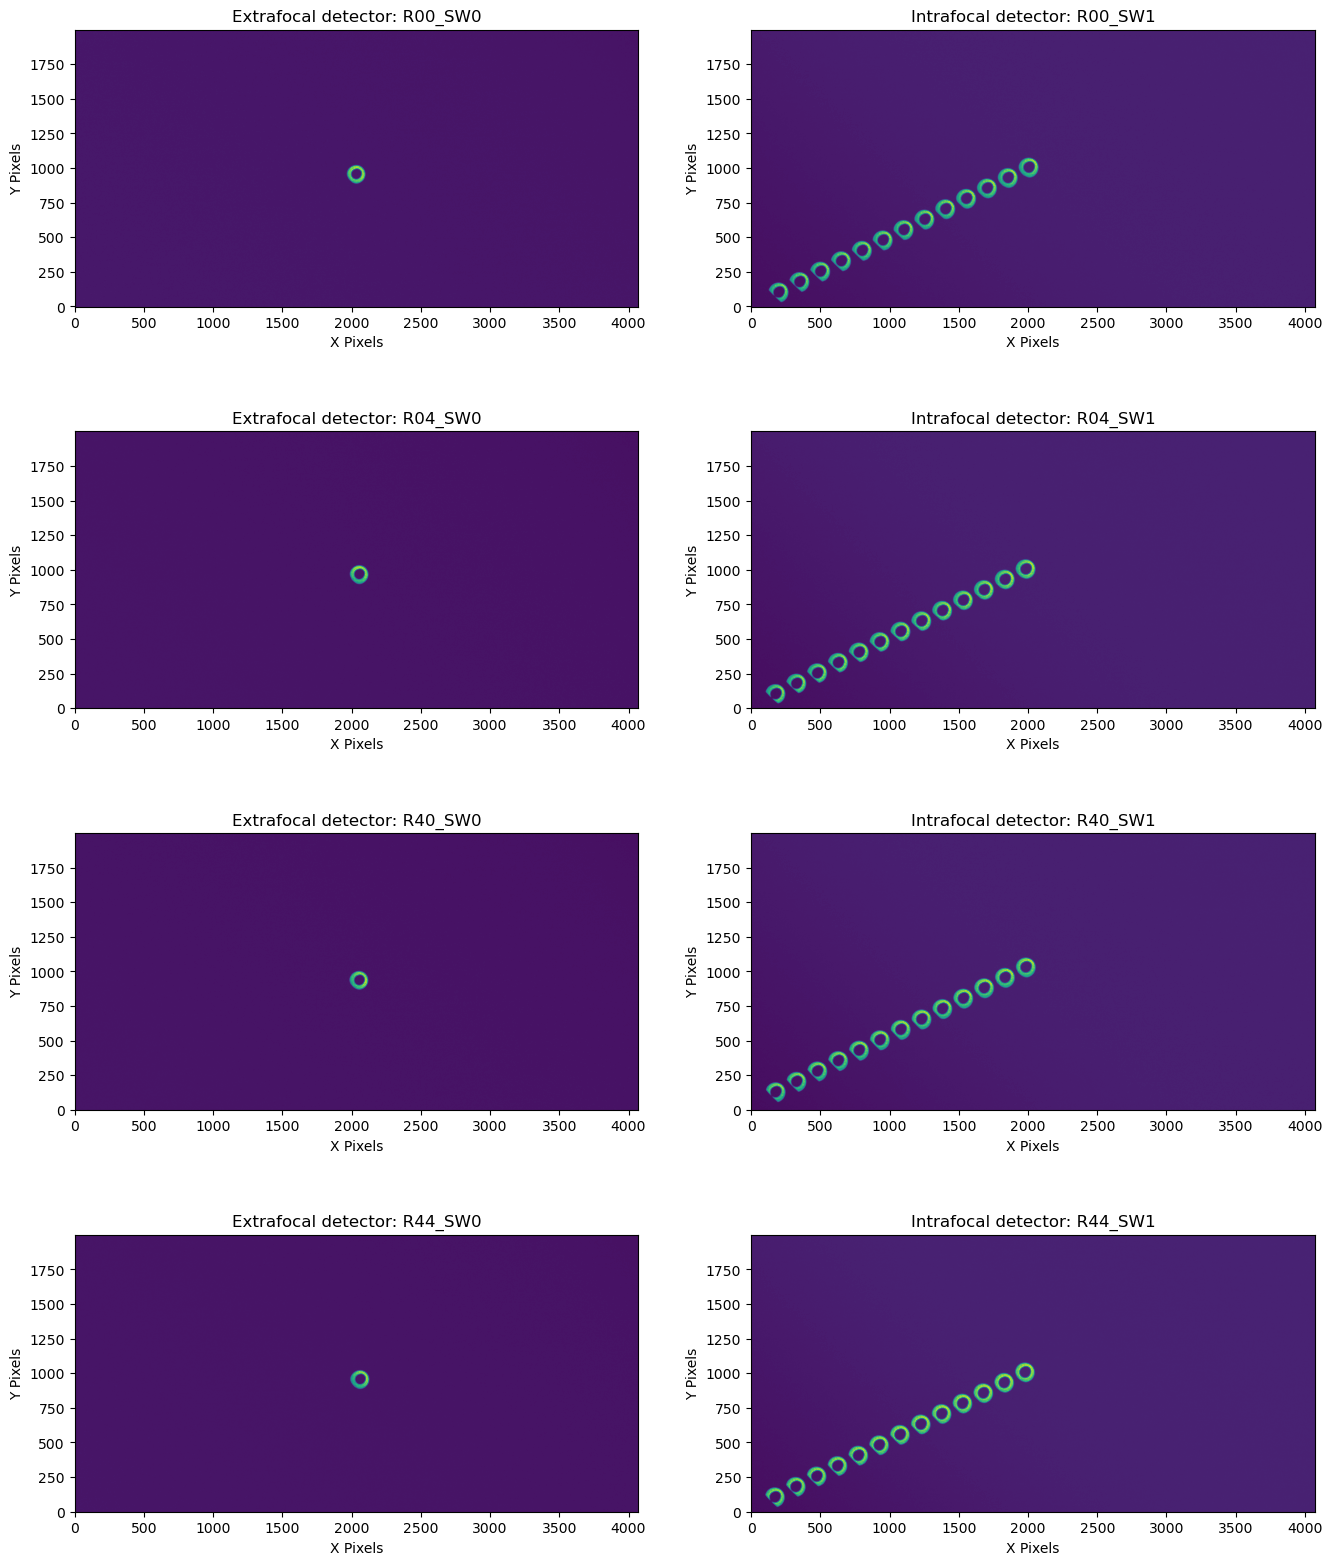

In [4]:
fig = plt.figure(figsize=(16, 20))
i = 1
for extraId in extraDetectorIds:
    fig.add_subplot(4, 2, i)
    extraIm = butler.get('postISRCCD', dataId=extraDataIds[str(extraId)], collections=['ts_imsim_1000'])
    plt.imshow(extraIm.getImage().getArray())
    extraDetectorName = extraIm.getDetector().getName()
    plt.xlabel('X Pixels')
    plt.ylabel('Y Pixels')
    plt.title(f'Extrafocal detector: {extraDetectorName}')
    fig.add_subplot(4, 2, i+1)
    intraIm = butler.get('postISRCCD', dataId=intraDataIds[str(extraId+1)], collections=['ts_imsim_1000'])
    plt.imshow(intraIm.getImage().getArray())
    intraDetectorName = intraIm.getDetector().getName()
    plt.title(f'Intrafocal detector: {intraDetectorName}')
    plt.xlabel('X Pixels')
    plt.ylabel('Y Pixels')
    i += 2

Let's take a closer look at the donuts by loading the `DonutStamps` for one of the detectors.

In [5]:
dataIdExtra['detector'] = 203
donutStampsIntra = butler.get('donutStampsIntra', dataId=dataIdExtra, collections=['ts_imsim_1000'])

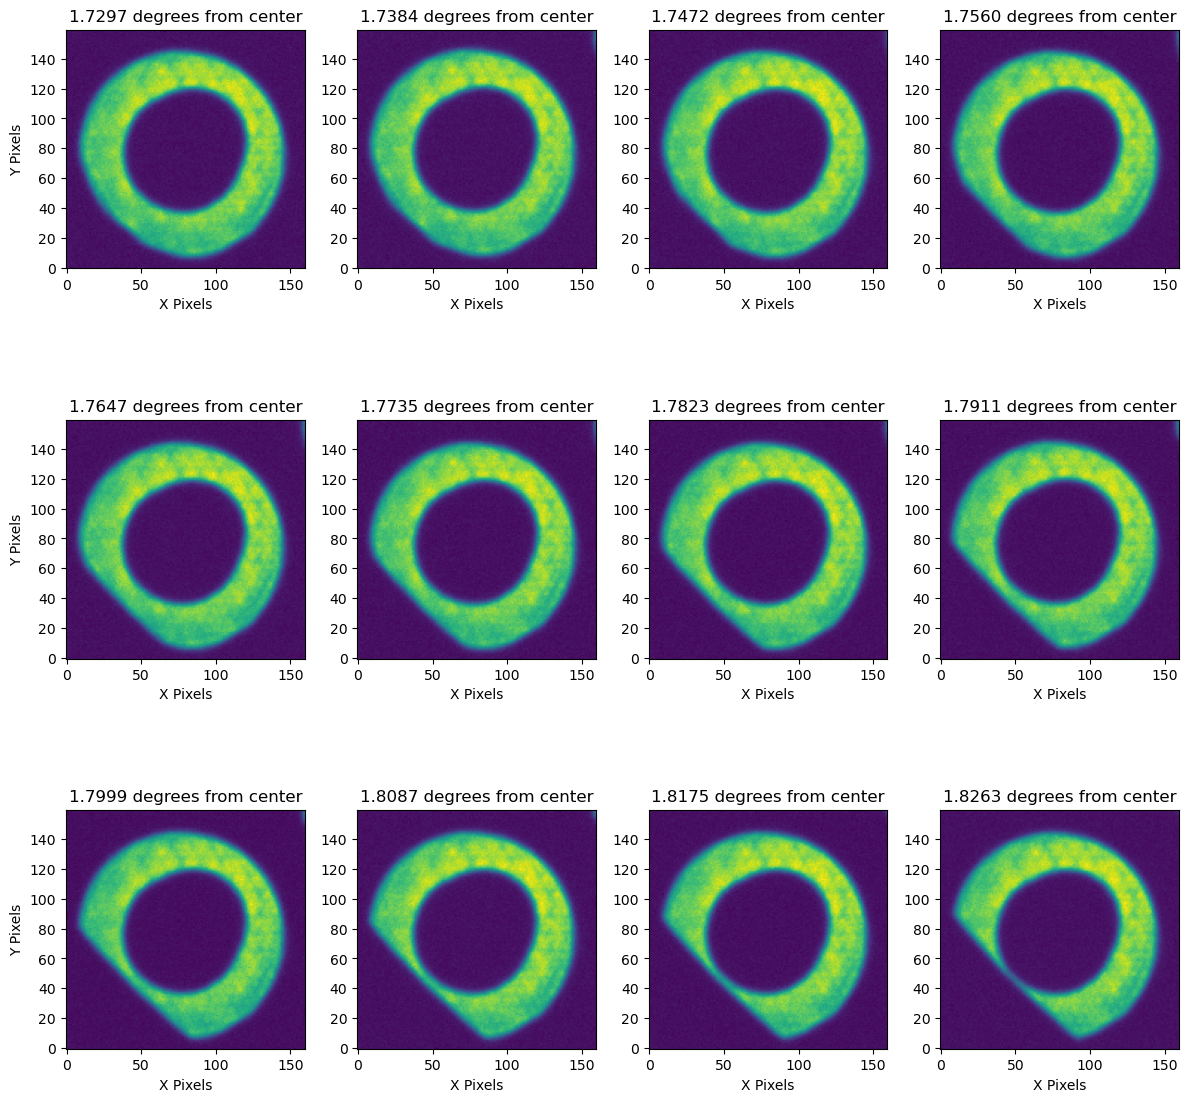

In [6]:
fig = plt.figure(figsize=(12, 12))
distToCenterVals = []
for i in range(12):
    fig.add_subplot(3, 4, i+1)
    dStamp = donutStampsIntra[i]
    plt.imshow(dStamp.stamp_im.getImage().getArray())
    ra = dStamp.sky_position[0].asDegrees()
    dec = dStamp.sky_position[1].asDegrees()
    distToCenter = np.sqrt((ra)**2 + dec**2)
    distToCenterVals.append(distToCenter)
    plt.title(f'{distToCenter:.4f} degrees from center')
    plt.xlabel('X Pixels')
    if i in [0, 4, 8]:
        plt.ylabel('Y Pixels')
plt.tight_layout()

Finally, we show the masks that are used in the closed loop and display that the existing model adds vignetting when calculating the masks.

In [7]:
# Load an instrument. Default is LSSTCam which we are using.
inst = Instrument()

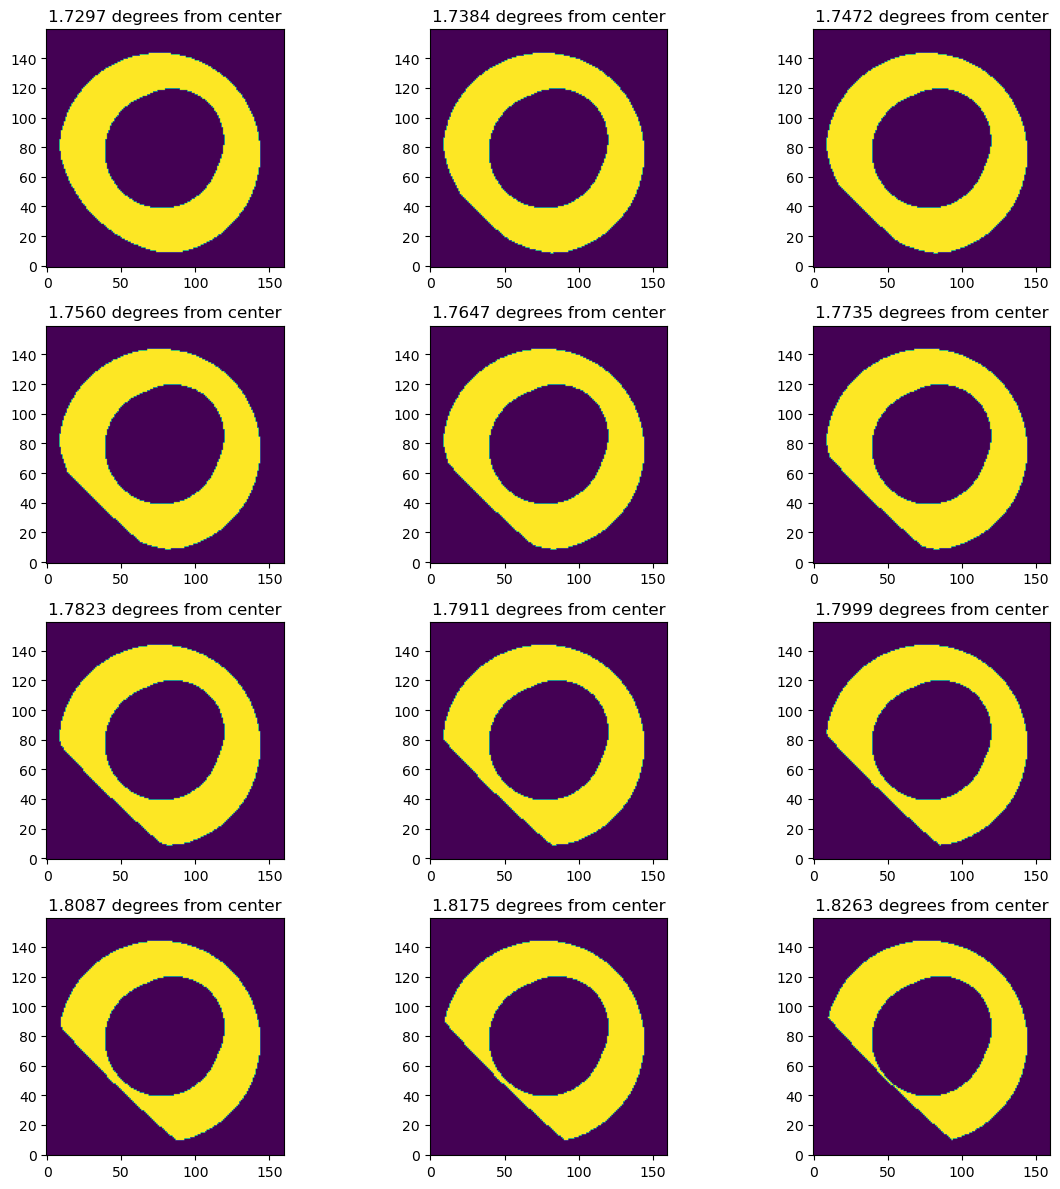

In [8]:
fig = plt.figure(figsize=(12, 12))
distToCenterVals = []
for i in range(12):
    fig.add_subplot(4, 3, i+1)
    dStamp = donutStampsIntra[i]
    dStamp.makeMask(inst)
    plt.imshow(dStamp.stamp_im.mask.getArray())
    ra = donutStampsIntra[i].sky_position[0].asDegrees()
    dec = donutStampsIntra[i].sky_position[1].asDegrees()
    distToCenter = np.sqrt((ra)**2 + dec**2)
    distToCenterVals.append(distToCenter)
    plt.title(f'{distToCenter:.4f} degrees from center')
plt.tight_layout()

A demonstration using the new mask model in `ts_wep` shows the elements of the Rubin system that contribute to the shape of the mask model we see above at 1.76 degrees from the center of the focal plane.

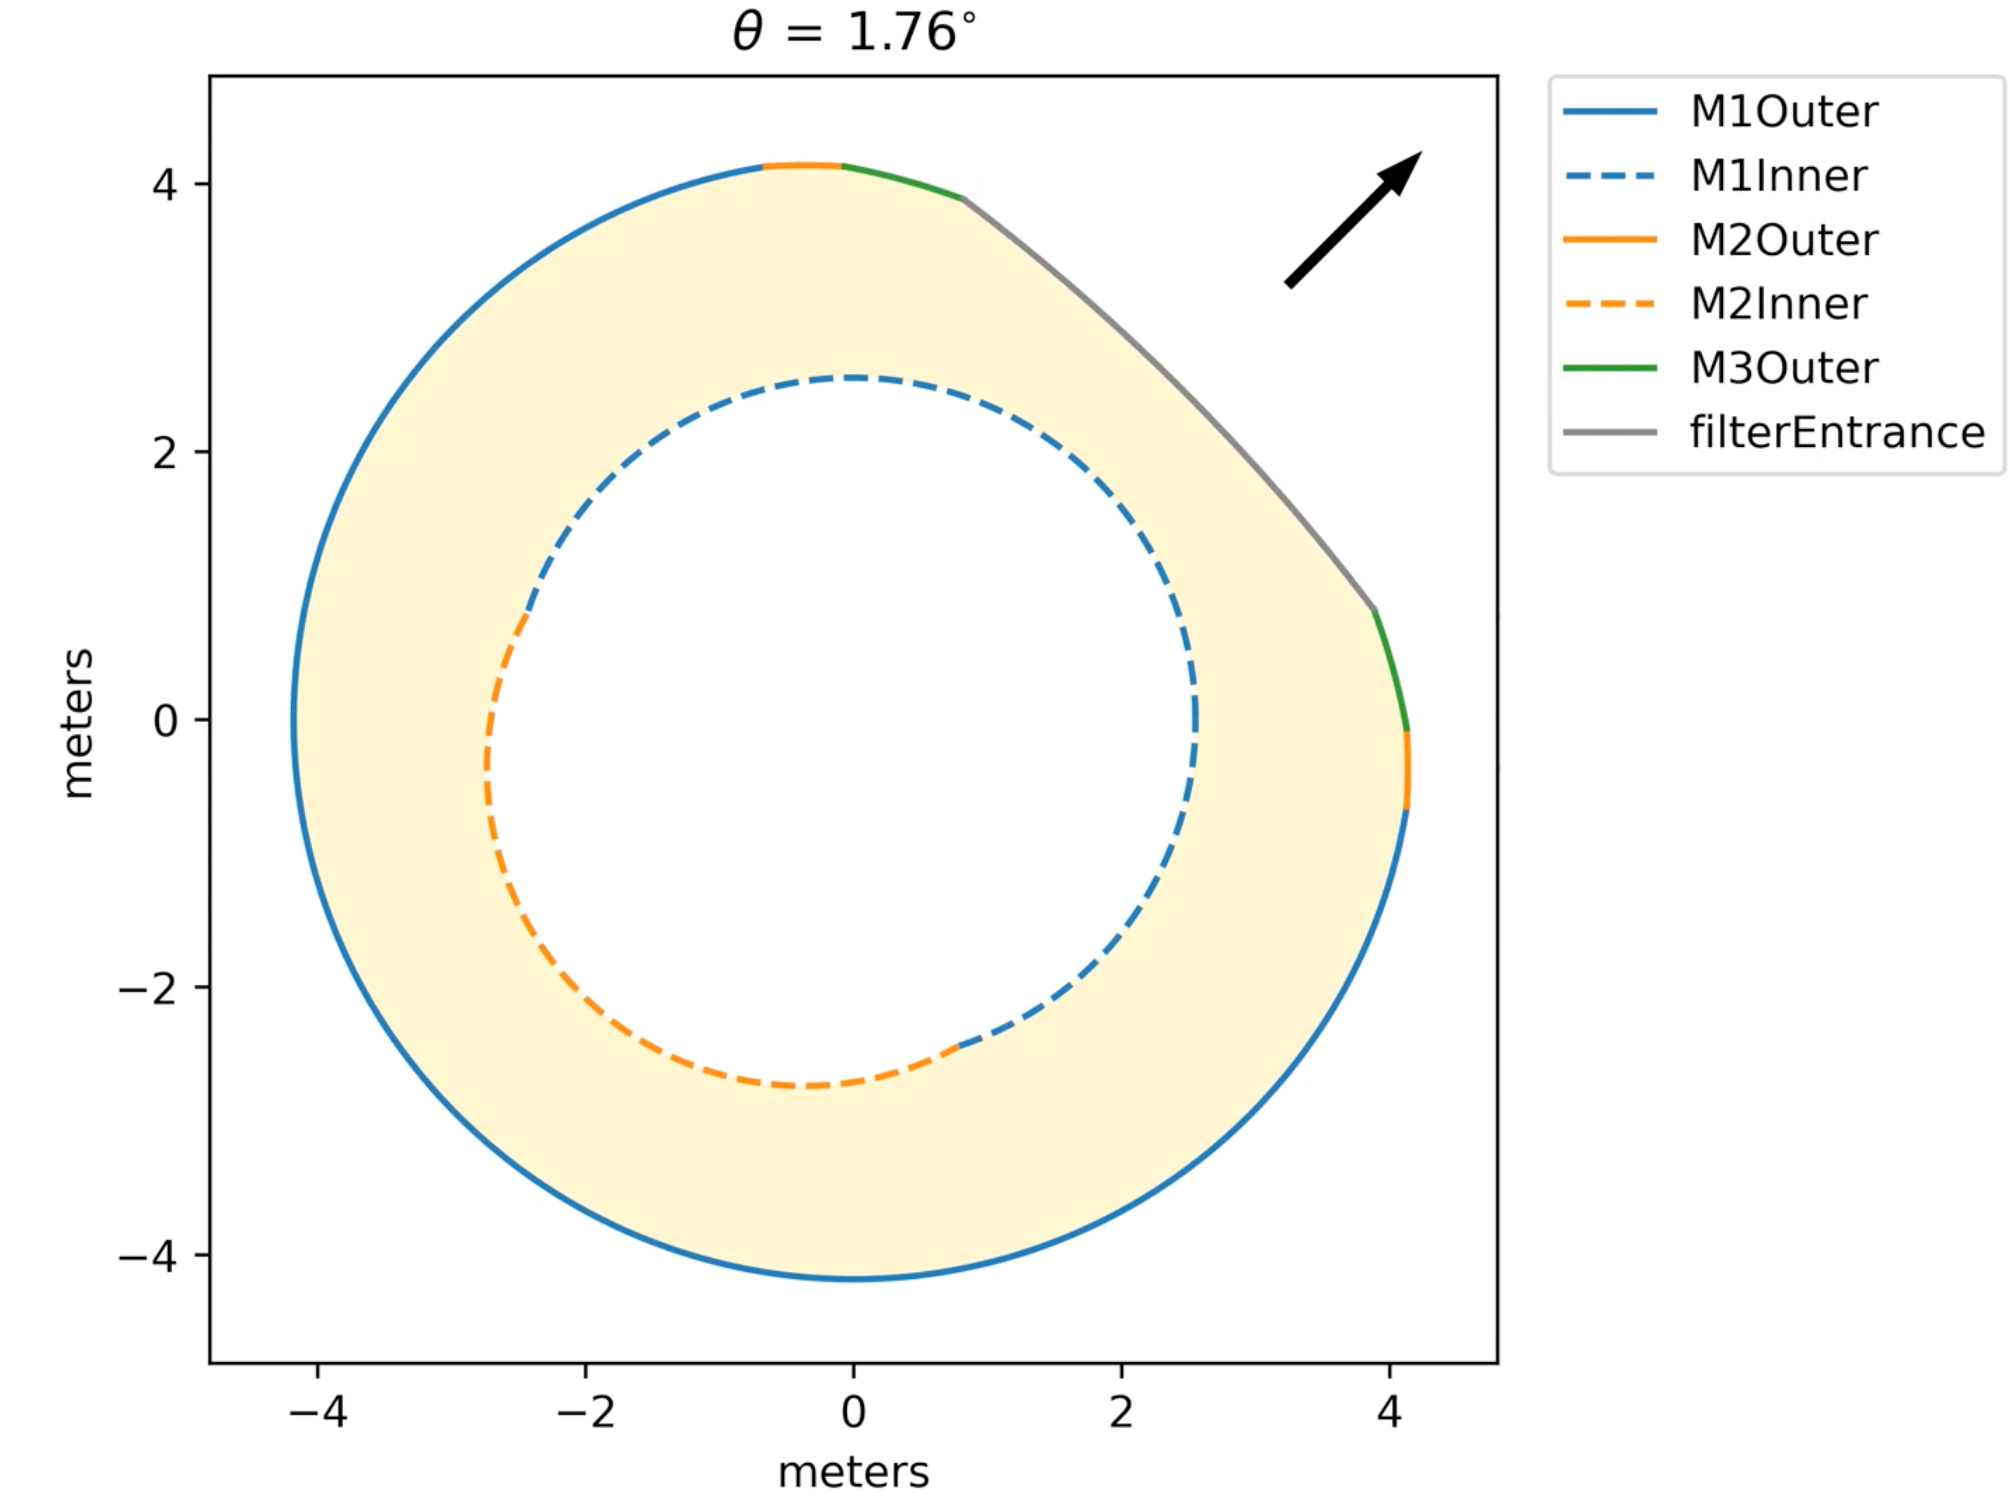

In [9]:
Image('mask_model_1.76.png')

## Zernike Estimation Performance with Vignetted Donuts <a id='zernike_estimation'></a>

For the rest of the notebook we use a series of runs in which we take a single extra-focal donut always at the same location and a single intra-focal donut at a different distance from the center of the field and run the full closed loop simulation. 

In this section for each wavefront sensor pair we load the Zernike coefficients from the first iteration of the closed loop. We then compare these results with the OPD values to see how well we can reproduce the true values with varying levels of vignetting.

### TIE

First we show the results using the updated version of the Transport of Intesity Equation (TIE) algorithm. For more details on the updates to the TIE algorithm in WEP see [this confluence page](https://confluence.lsstcorp.org/display/LTS/WEP+Estimation+Algorithms).

In [10]:
field_distances = []
for dir_name in os.listdir(supporting_data_folder):
    if dir_name == 'catalogs':
        continue
    field_dist = dir_name.split('_')[2]
    if field_dist == 'all':
        continue
    field_distances.append(field_dist)
field_distances.sort()

In [11]:
iterZerns = {}
for iter_num in range(10):
    detectorZerns = {}
    for extraId in extraDetectorIds:
        dataIdExtra = extraDataIds[str(extraId)]
        zernVals = []
        opdVals = []
        for field_dist in field_distances:
            # Repository with simulated data
            with open(os.path.join(f'{supporting_data_folder}/single_donut_{field_dist}/iter{iter_num}/img/wfs.zer'), 'r') as f:
                wfs_truth = yaml.safe_load(f)
                wfs_str_list = wfs_truth[extraId]
                zernVals.append(np.loadtxt(wfs_str_list))
            with open(os.path.join(f'{supporting_data_folder}/single_donut_{field_dist}/iter{iter_num}/img/opd.zer'), 'r') as f:
                opd_truth = yaml.safe_load(f)
                opd_str_list = opd_truth[extraId]
                opdVals.append(np.loadtxt(opd_str_list))
        detectorZerns[f'{extraId}_wep'] = np.array(zernVals)
        detectorZerns[f'{extraId}_opd'] = np.array(opdVals)
    iterZerns[iter_num] = detectorZerns

In [12]:
# Load the OPD "Truth" information
with  open(os.path.join(f'{supporting_data_folder}/single_donut_{field_dist}/iter{iter_num}/img/opd.zer'), 'r') as f:
    opd_truth = yaml.safe_load(f)
for det_num in [191, 195, 199, 203]:
    opd_str_list = opd_truth[det_num]
    opd_truth[det_num] = np.loadtxt(opd_str_list)

In [13]:
camera = butler.get('camera', dataId={'instrument':'LSSTCam'}, collections='LSSTCam/calib/unbounded')

In [14]:
distToCenterVals = np.array(field_distances[:-1], dtype=float)

First, let's look at how the overall error in the wavefront estimate changes as a function of vignetting.

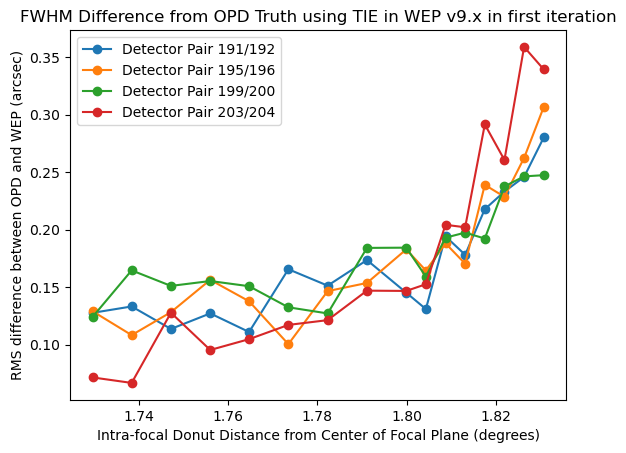

In [15]:
# Show zernikes on each sensor pair across different vignetting
i = 1
iter_num = 0
fig = plt.figure()
psfContribDict = {}
for extraId in extraDetectorIds:
    psfContrib = []
    for j in range(16):
        psfContrib.append(
            np.sqrt(np.nansum(np.square(
                convertZernikesToPsfWidth(
                    iterZerns[iter_num][f'{extraId}_wep'][j] - iterZerns[iter_num][f'{extraId}_opd'][j]/1e3
                )
            )))
        )
    plt.plot(
        distToCenterVals, psfContrib, '-o', label=f'Detector Pair {extraId}/{extraId+1}'
    )
    psfContribDict[extraId] = psfContrib
    i += 1
plt.ylabel('RMS difference between OPD and WEP (arcsec)')
plt.xlabel('Intra-focal Donut Distance from Center of Focal Plane (degrees)')
plt.title('FWHM Difference from OPD Truth using TIE in WEP v9.x in first iteration')
plt.legend()

This figure above shows the RMS difference between the OPD "truth" Zernike values and the TIE estimates as a function of distance from the center of the focal plane in the first iteration of the closed loop. As we can see after about 1.78 degrees there is a trend of larger errors in our estimate that continues out to the edge of the wavefront sensors at 1.83 degrees.

Below we show this combining the information from all 10 iterations and the trend is clearer in this combined data that smooths out the noise in individual iterations. It looks like we can estimate the Zernike values consistently well up to about 1.78 degrees and after that the accuracy of our estimates starts to deteriorate.

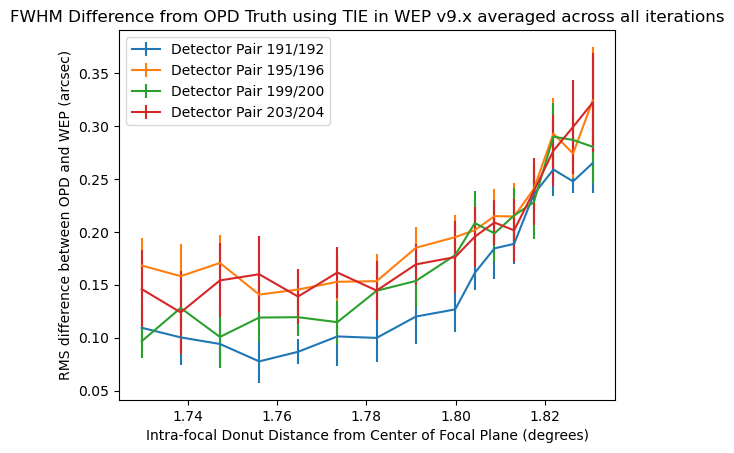

In [16]:
# Show zernikes on each sensor pair across different vignetting
i = 1
fig = plt.figure()
psfContribAllDict = {}
for extraId in extraDetectorIds:
    psfContribAll = []
    for iter_num in range(10):
        psfContrib = []
        for j in range(16):
            psfContrib.append(
                np.sqrt(np.nansum(np.square(
                    convertZernikesToPsfWidth(
                        iterZerns[iter_num][f'{extraId}_wep'][j] - iterZerns[iter_num][f'{extraId}_opd'][j]/1e3
                    )
                )))
            )
        psfContribAll.append(psfContrib)
    psfContrib = np.mean(psfContribAll, axis=0)
    psfContribStd = np.std(psfContribAll, axis=0)
    psfContribAllDict[extraId] ={}
    psfContribAllDict[extraId]['mean'] = psfContrib
    psfContribAllDict[extraId]['std'] = psfContribStd
    plt.errorbar(
        distToCenterVals, psfContrib, yerr=psfContribStd, label=f'Detector Pair {extraId}/{extraId+1}'
    )
    i += 1
plt.ylabel('RMS difference between OPD and WEP (arcsec)')
plt.xlabel('Intra-focal Donut Distance from Center of Focal Plane (degrees)')
plt.title('FWHM Difference from OPD Truth using TIE in WEP v9.x averaged across all iterations')
plt.legend()

We see that there is a steady increase in the overall wavefront error as we move closer to the edge of the intra-focal sensor and vignetting increases.
This confirms that vignetting affects how well we can measure the Zernikes.


To learn more let's drill down into the errors in individual Zernike measurements as a function of distance from the center of the focal plane.

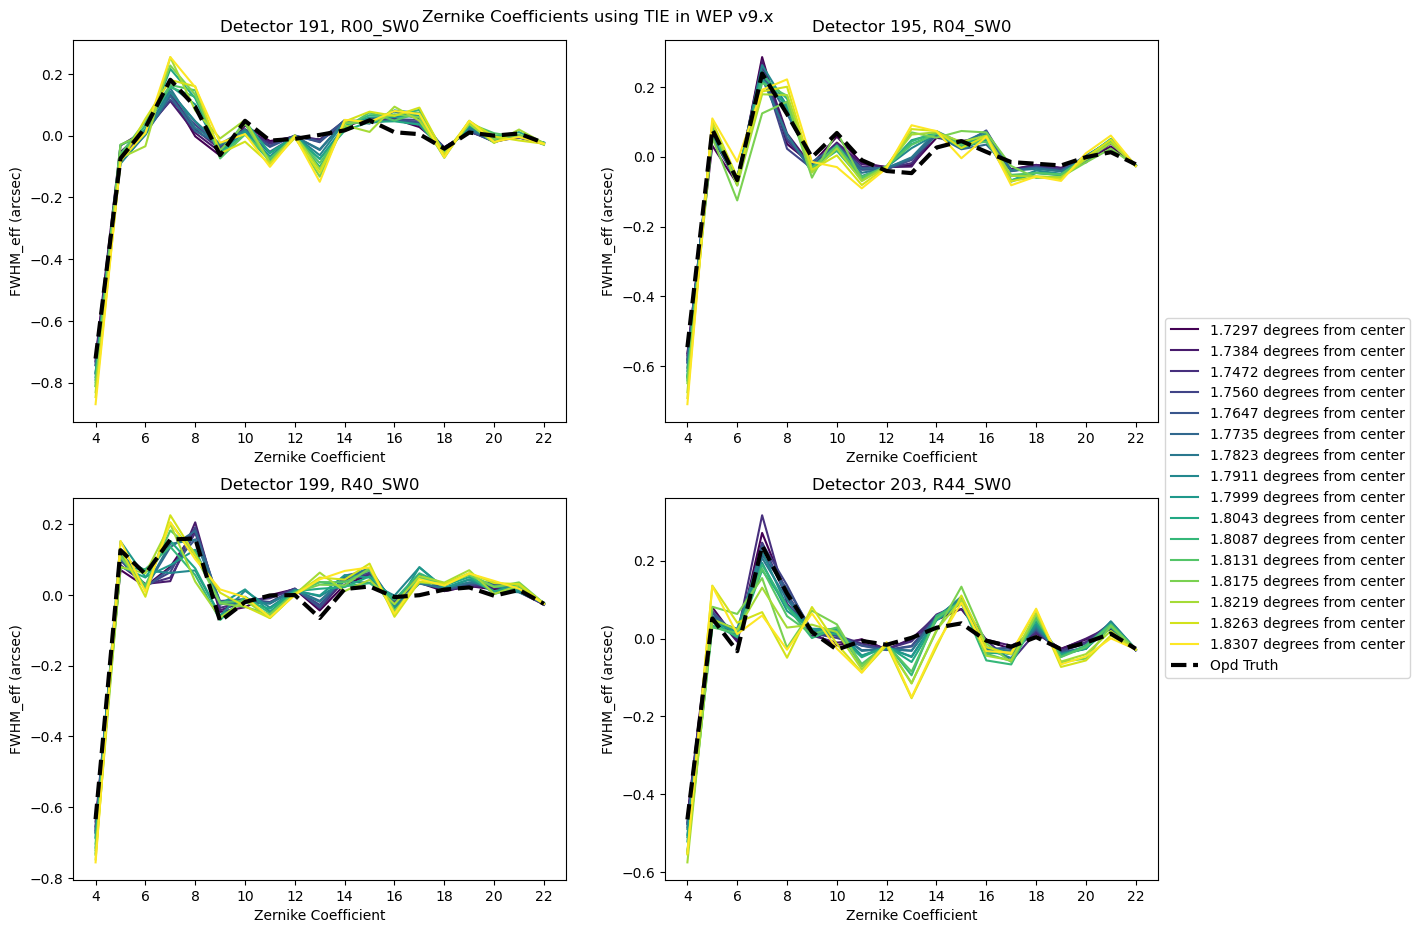

In [17]:
# Show zernikes on each sensor across different vignetting
i = 1
iter_num = 0
fig = plt.figure(figsize=(14, 10))

n = len(distToCenterVals)
colors = plt.cm.viridis(np.linspace(0,1,n))

for extraId in extraDetectorIds:
    fig.add_subplot(2, 2, i)
    for j in range(16):
        plt.plot(np.arange(4, 23), convertZernikesToPsfWidth(iterZerns[iter_num][f'{extraId}_wep'][j]), label=f'{distToCenterVals[j]:.4f} degrees from center', c=colors[j])
    plt.plot(np.arange(4, 23), convertZernikesToPsfWidth(iterZerns[iter_num][f'{extraId}_opd'][j]/1e3), '--', label=f'Opd Truth', lw=3, c='k')
    plt.title(f'Detector {extraId}, {camera[extraId].getName()}')
    plt.ylabel('FWHM_eff (arcsec)')
    plt.xlabel('Zernike Coefficient')
    plt.xticks(np.arange(4, 23, 2))
    i+=1
ax = plt.gca()
ax.legend(loc='center left', bbox_to_anchor=(1, 1))
plt.suptitle('Zernike Coefficients using TIE in WEP v9.x')
plt.subplots_adjust(top=0.95)

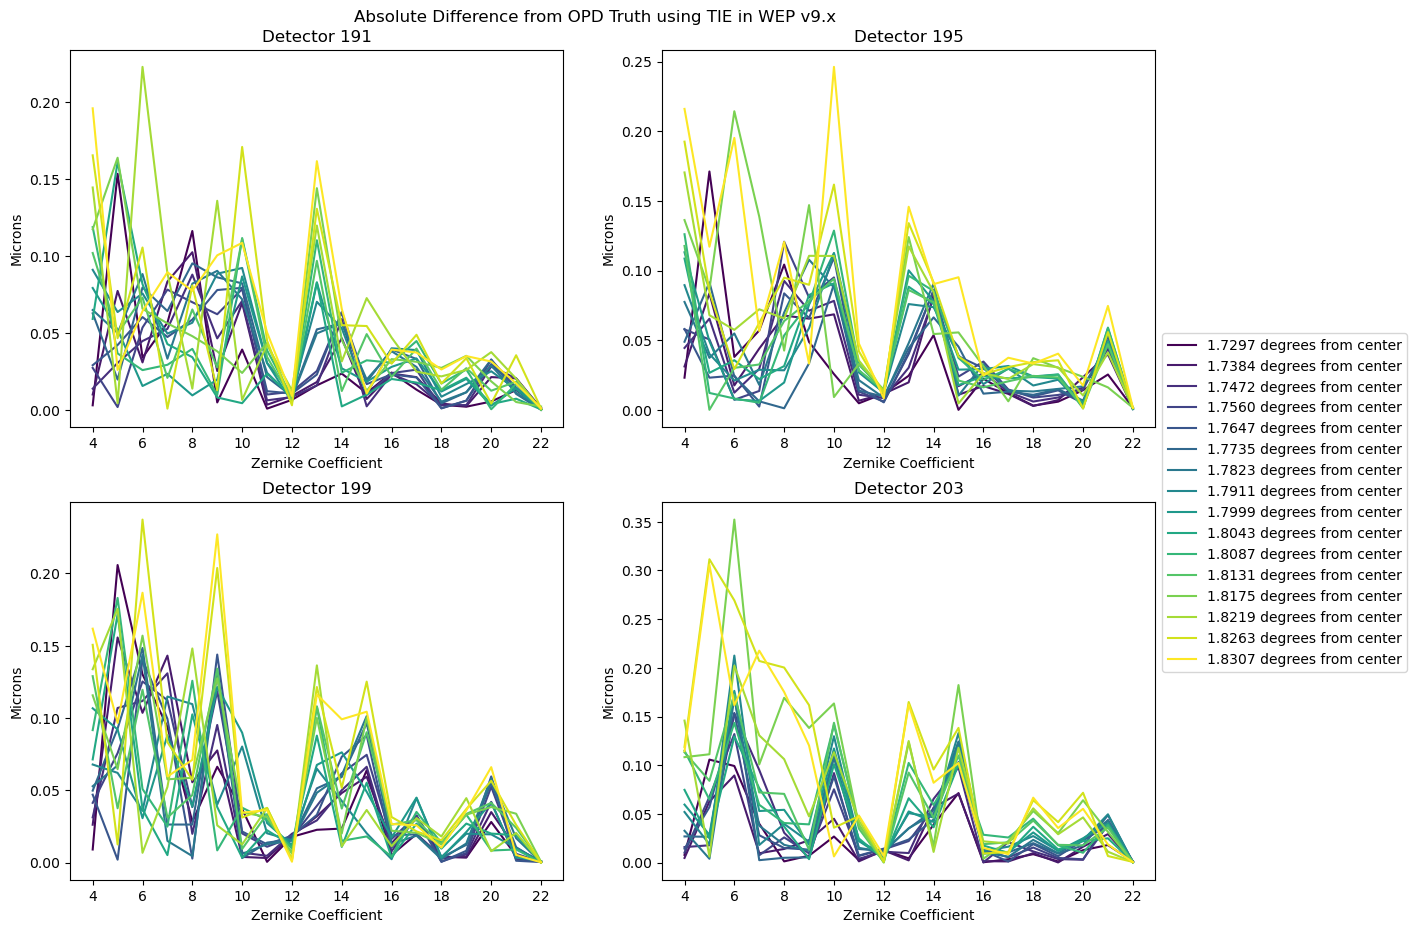

In [18]:
# Show zernikes on each sensor across different vignetting
i = 1
iter_num = 0
fig = plt.figure(figsize=(14, 10))
for extraId in extraDetectorIds:
    fig.add_subplot(2, 2, i)
    for j in range(16):
        plt.plot(
            np.arange(4, 23), 
            np.abs(iterZerns[iter_num][f'{extraId}_wep'][j]-iterZerns[iter_num][f'{extraId}_opd'][j]/1e3), 
            label=f'{distToCenterVals[j]:.4f} degrees from center',
            c=colors[j]
        )
        plt.xticks(np.arange(4, 23, 2))
    plt.title(f'Detector {extraId}')
    plt.ylabel('Microns')
    plt.xlabel('Zernike Coefficient')
    i+=1
ax = plt.gca()
ax.legend(loc='center left', bbox_to_anchor=(1, 1))
plt.suptitle('Absolute Difference from OPD Truth using TIE in WEP v9.x')
plt.subplots_adjust(top=0.94)

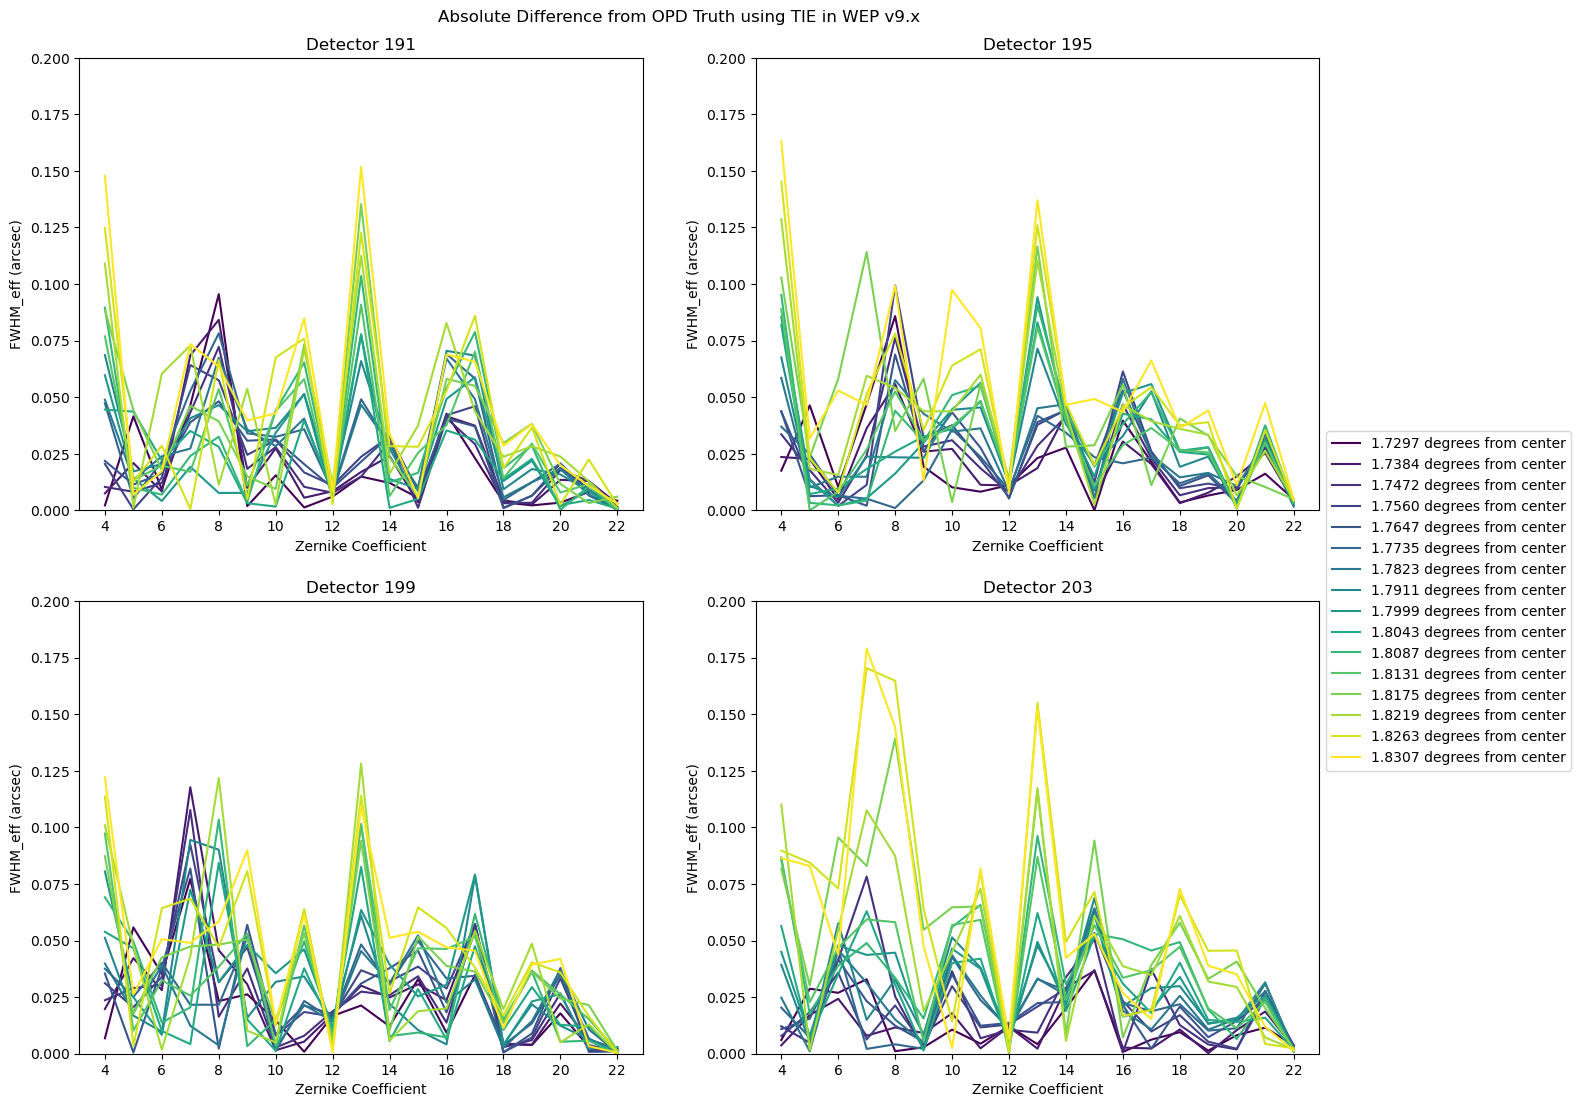

In [19]:
# Show zernikes on each sensor across different vignetting
i = 1
iter_num = 0
fig = plt.figure(figsize=(16, 12))
for extraId in extraDetectorIds:
    fig.add_subplot(2, 2, i)
    for j in range(16):
        plt.plot(
            np.arange(4, 23), 
            convertZernikesToPsfWidth(np.abs(iterZerns[iter_num][f'{extraId}_wep'][j]-iterZerns[iter_num][f'{extraId}_opd'][j]/1e3)), 
            label=f'{distToCenterVals[j]:.4f} degrees from center', 
            c=colors[j]
        )
        plt.xticks(np.arange(4, 23, 2))
    plt.title(f'Detector {extraId}')
    plt.ylabel('FWHM_eff (arcsec)')
    plt.xlabel('Zernike Coefficient')
    plt.ylim(0, 0.20)
    i+=1
ax = plt.gca()
ax.legend(loc='center left', bbox_to_anchor=(1, 1))
plt.suptitle('Absolute Difference from OPD Truth using TIE in WEP v9.x')
plt.subplots_adjust(top=0.94)

We can see that the WEP estimates do not display overall clear trends when looking at the errors across all of the estimates of individual Zernikes. There is some evidence in the errors looking at Z4, Z10, Z13, Z15, Z18-Z21 that these are affected by vignetting as they display some increase in errors as we move further toward the edge of the focal plane but the differences look very small and inconsistent across all wavefront sensors. 

This lack of a clear trend is different from what we saw with older versions of TIE. However, the most important difference in this new version is that the scale of these individual errors in the WEP estimates is much smaller than those of the original TIE from earlier versions of WEP (see the plots in the old version of this notebook [here](wepVignettedPerformanceLimits.ipynb)). Below we show the improvement in the new version compared to the old version:

In [20]:
old_supporting_data_folder = '/sdf/group/rubin/repo/aos_imsim/brycek/ts_analysis_notebooks_supporting_data/vignette_tests'

In [21]:
iterZernsOldTie = {}
for iter_num in range(10):
    detectorZerns = {}
    for extraId in extraDetectorIds:
        dataIdExtra = extraDataIds[str(extraId)]
        zernVals = []
        opdVals = []
        for field_dist in field_distances:
            # Repository with simulated data
            with open(os.path.join(f'{old_supporting_data_folder}/single_donut_{field_dist}/iter{iter_num}/img/wfs.zer'), 'r') as f:
                wfs_truth = yaml.safe_load(f)
                wfs_str_list = wfs_truth[extraId]
                zernVals.append(np.loadtxt(wfs_str_list))
            with open(os.path.join(f'{old_supporting_data_folder}/single_donut_{field_dist}/iter{iter_num}/img/opd.zer'), 'r') as f:
                opd_truth = yaml.safe_load(f)
                opd_str_list = opd_truth[extraId]
                opdVals.append(np.loadtxt(opd_str_list))
        detectorZerns[f'{extraId}_wep'] = np.array(zernVals)
        detectorZerns[f'{extraId}_opd'] = np.array(opdVals)
    iterZernsOldTie[iter_num] = detectorZerns

In [22]:
def plot_overall_fig_tie():
    # Show zernikes on each sensor across different vignetting
    i = 1
    iter_num = 0
    fig = plt.figure(figsize=(14, 14))
    fig.add_subplot(2,2,2)
    for j in range(16):
        diff = np.zeros(19)
        for extraId in extraDetectorIds:
            diff += np.abs(iterZerns[iter_num][f'{extraId}_wep'][j]-iterZerns[iter_num][f'{extraId}_opd'][j]/1e3)
        plt.plot(
            np.arange(4, 23),
            convertZernikesToPsfWidth(diff / 4),
            label=f'{distToCenterVals[j]:.4f} degrees from center',
            c=colors[j]
        )
    plt.xticks(np.arange(4, 23, 2))
    plt.ylim(-0.02, 0.50)
    plt.ylabel('< |WEP-OPD| > (arcsec)')
    plt.xlabel('Zernike Coefficient')
    #plt.legend()
    plt.title('Mean Abs. Diff. from Truth w/ TIE in WEP v9.1.0 across 4 CWFS')
    
    fig.add_subplot(2,2,1)
    for j in range(16):
        diff = np.zeros(19)
        for extraId in extraDetectorIds:
            diff += np.abs(iterZernsOldTie[iter_num][f'{extraId}_wep'][j]-iterZernsOldTie[iter_num][f'{extraId}_opd'][j]/1e3)
        plt.plot(
            np.arange(4, 23),
            convertZernikesToPsfWidth(diff / 4),
            label=f'{distToCenterVals[j]:.4f} degrees from center',
            c=colors[j]
        )
    plt.xticks(np.arange(4, 23, 2))
    plt.ylim(-0.02, 0.50)
    plt.ylabel('< |WEP-OPD| > (arcsec)')
    plt.xlabel('Zernike Coefficient')
    #plt.legend()
    plt.title('Mean Abs. Diff. from Truth w/ TIE in WEP v8.3.0 across 4 CWFS')
    
    fig.add_subplot(2, 1, 2)
    for j in range(16):
        diff = np.zeros(19)
        for extraId in extraDetectorIds:
            diff += np.abs(iterZernsOldTie[iter_num][f'{extraId}_wep'][j]-iterZernsOldTie[iter_num][f'{extraId}_opd'][j]/1e3) - \
            np.abs(iterZerns[iter_num][f'{extraId}_wep'][j]-iterZerns[iter_num][f'{extraId}_opd'][j]/1e3)
        plt.plot(
            np.arange(4, 23),
            convertZernikesToPsfWidth(diff / 4),
            label=f'{distToCenterVals[j]:.4f} degrees from center',
            c=colors[j]
        )
    plt.xticks(np.arange(4, 23, 2))
    
    plt.legend(ncol=2)
    plt.title('Mean Improvement in Zernike estimates with TIE in WEP v9.x compared to v8.3')
    plt.ylabel('v8.3$_{<|WEP-OPD|>}$ - v9.1$_{<|WEP-OPD|>}$ (arcsec)')
    plt.xlabel('Zernike Coefficient')

Below we show the average deviation from the truth across the 4 CWFS detector pairs as a function of Zernike number for the two version of the TIE implementation in the top two panels. In the bottom panel we compare the two by subtracting the v9.1 errors from the v8.3 errors so that values greater than 0 indicate the error is larger in v8.3 and vice versa.

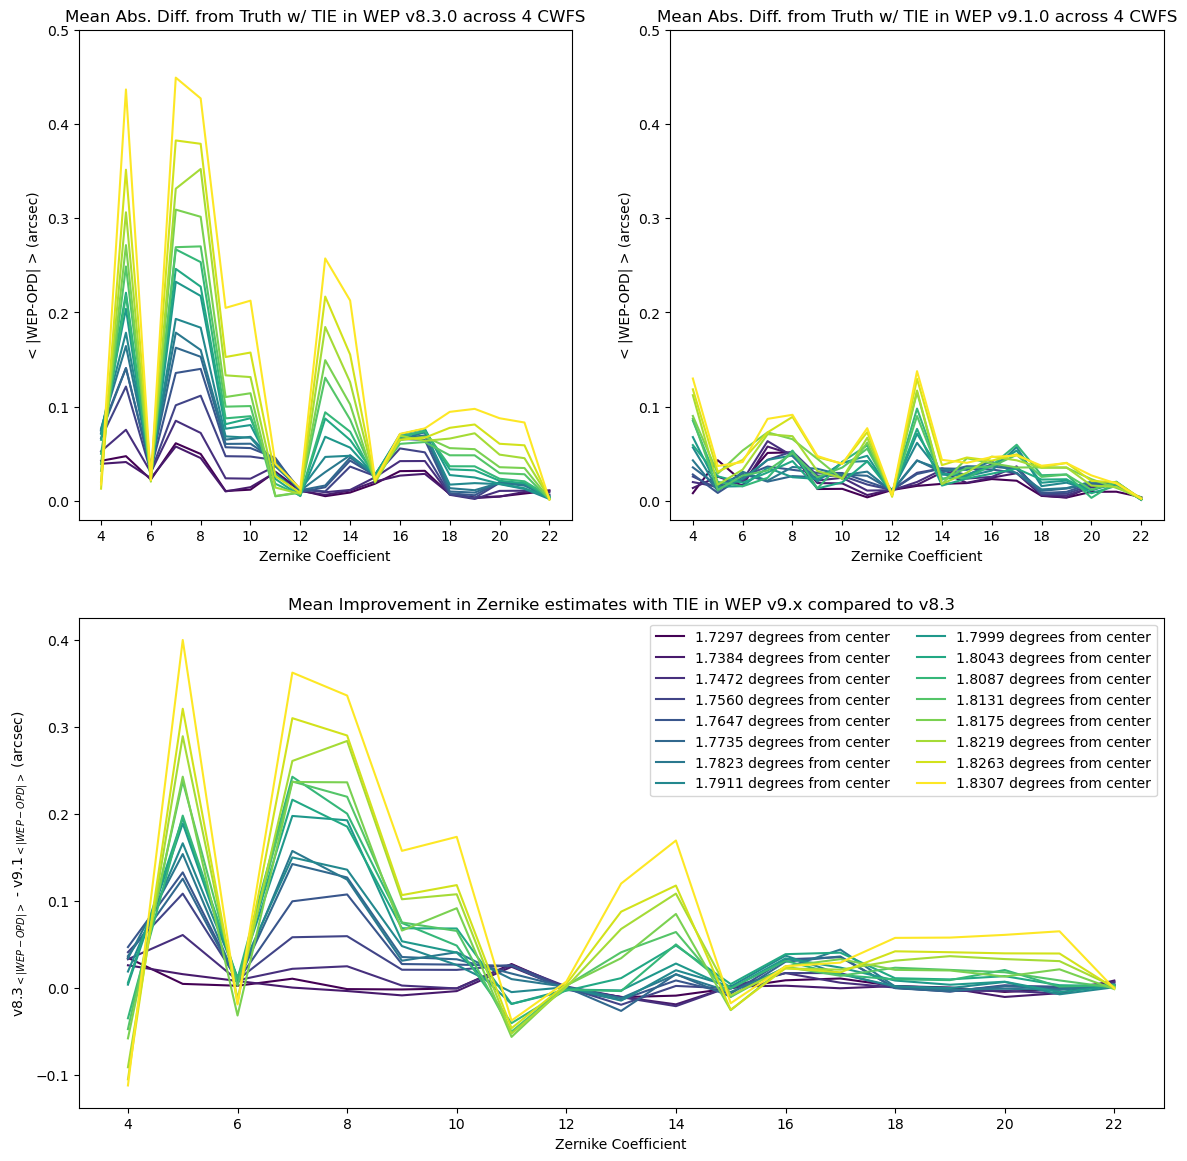

In [23]:
plot_overall_fig_tie()

As mentioned above, values in the bottom panel greater than 0 indicate that the error in v8.3 is higher than in v9.1. We can see that in almost every combination of distance from the center of the focal plane and Zernike number the v9 error is less than v8.3 showing that there is a clear improvement in v9.1. In some cases this improvement is up to 0.4 arcseconds.

### `danish`

Let's conduct the same analysis looking at results using `danish` to estimate the Zernike coefficients.

In [24]:
# Repository with simulated data
danish_supporting_data_folder = '/sdf/group/rubin/repo/aos_imsim/brycek/ts_analysis_notebooks_supporting_data/vignette_tests_danish/'

In [25]:
iterZernsDanish = {}
for iter_num in range(10):
    detectorZerns = {}
    for extraId in extraDetectorIds:
        dataIdExtra = extraDataIds[str(extraId)]
        zernVals = []
        opdVals = []
        for field_dist in field_distances:
            # Repository with simulated data
            with open(os.path.join(f'{danish_supporting_data_folder}/single_donut_{field_dist}/iter{iter_num}/img/wfs.zer'), 'r') as f:
                wfs_truth = yaml.safe_load(f)
                wfs_str_list = wfs_truth[extraId]
                zernVals.append(np.loadtxt(wfs_str_list))
            with open(os.path.join(f'{danish_supporting_data_folder}/single_donut_{field_dist}/iter{iter_num}/img/opd.zer'), 'r') as f:
                opd_truth = yaml.safe_load(f)
                opd_str_list = opd_truth[extraId]
                opdVals.append(np.loadtxt(opd_str_list))
        detectorZerns[f'{extraId}_wep'] = np.array(zernVals)
        detectorZerns[f'{extraId}_opd'] = np.array(opdVals)
    iterZernsDanish[iter_num] = detectorZerns

Once again we start by looking at how the overall error in the wavefront estimate changes as a function of vignetting.

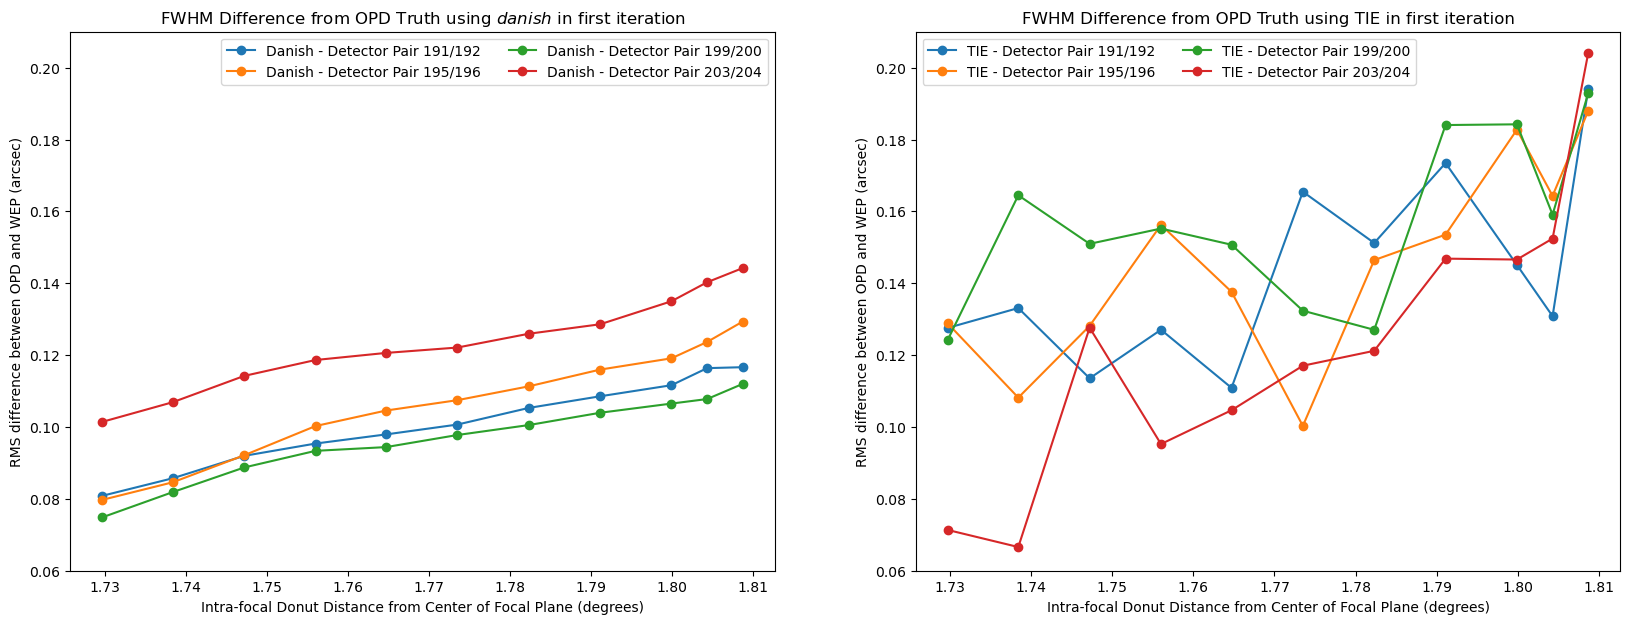

In [26]:
# Show zernikes on each sensor pair across different vignetting
i = 1
iter_num = 0
fig = plt.figure(figsize=(20, 7))
fig.add_subplot(1,2,1)
for extraId in extraDetectorIds:
    psfContribDanish = []
    for j in range(11):
        psfContribDanish.append(
            np.sqrt(np.nansum(np.square(
                convertZernikesToPsfWidth(
                    iterZernsDanish[iter_num][f'{extraId}_wep'][j] - iterZernsDanish[iter_num][f'{extraId}_opd'][j]/1e3
                )
            )))
        )
    plt.plot(
        distToCenterVals[:11], psfContribDanish, '-o', label=f'Danish - Detector Pair {extraId}/{extraId+1}', c=f'C{i-1}'
    )
    i += 1
plt.ylabel('RMS difference between OPD and WEP (arcsec)')
plt.xlabel('Intra-focal Donut Distance from Center of Focal Plane (degrees)')
plt.title('FWHM Difference from OPD Truth using $danish$ in first iteration')
plt.legend(ncol=2)
plt.ylim(0.06, 0.21)

fig.add_subplot(1,2,2)
for i, extraId in enumerate(extraDetectorIds):
    plt.plot(
        distToCenterVals[:11], psfContribDict[extraId][:11], '-o', label=f'TIE - Detector Pair {extraId}/{extraId+1}', c=f'C{i}'
    )
    i += 1
    plt.ylim(0.06, 0.21)
plt.ylabel('RMS difference between OPD and WEP (arcsec)')
plt.xlabel('Intra-focal Donut Distance from Center of Focal Plane (degrees)')
plt.title('FWHM Difference from OPD Truth using TIE in first iteration')
plt.legend(ncol=2)

This figure above shows the difference between the OPD "truth" Zernike values and the `danish` estimates as a function of distance from the center of the focal plane in the first iteration of the closed loop in the left panel. Unlike the plot with the new TIE (shown in right panel) we clearly see a trend showing increasing wavefront error as we move toward the edge of the focal plane across the entire range tested. In addition, the wavefront errors with `danish` are consistently lower than the errors found using the new TIE. Finally, we see that the x-axis on the plot ends at 1.81 degrees rather than the 1.83 degrees we were able to get to with new TIE. `danish` is unable to deal with vignetting past this point and the WEP code fails at this earlier distance from the center of the focal plane.

Below we show the same plot combining the information from all 10 iterations and the trend is not as clear in this combined data but the errors are lower when we move further to the edge of the focal plane when we use `danish` than when we use the TIE.

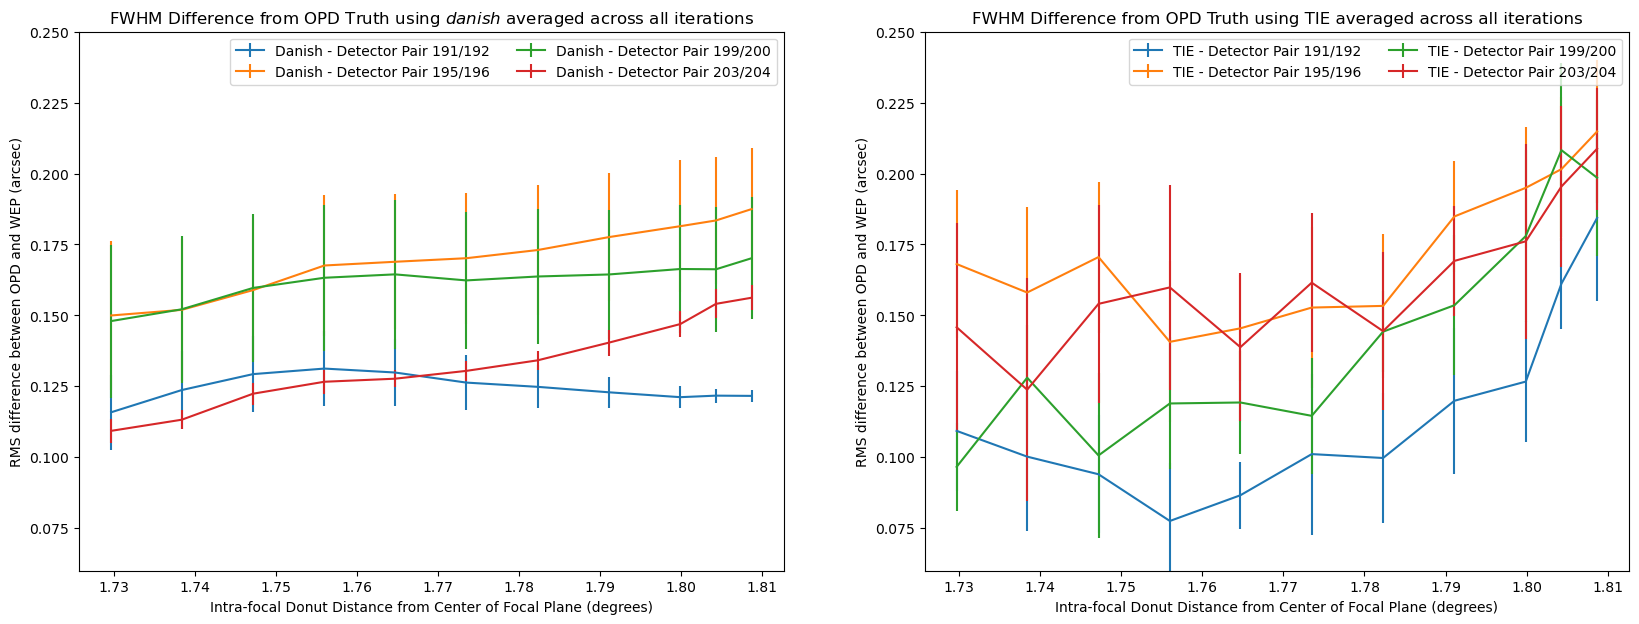

In [27]:
# Show zernikes on each sensor pair across different vignetting
i = 1
fig = plt.figure(figsize=(20, 7))
fig.add_subplot(1,2,1)
for extraId in extraDetectorIds:
    psfContribAllDanish = []
    for iter_num in range(10):
        psfContrib = []
        for j in range(11):
            psfContrib.append(
                np.sqrt(np.nansum(np.square(
                    convertZernikesToPsfWidth(
                        iterZernsDanish[iter_num][f'{extraId}_wep'][j] - iterZernsDanish[iter_num][f'{extraId}_opd'][j]/1e3
                    )
                )))
            )
        psfContribAllDanish.append(psfContrib)
    psfContribDanish = np.mean(psfContribAllDanish, axis=0)
    plt.errorbar(
        distToCenterVals[:11], psfContribDanish, yerr=np.std(psfContribAllDanish, axis=0), label=f'Danish - Detector Pair {extraId}/{extraId+1}'
    )
    i += 1
plt.ylabel('RMS difference between OPD and WEP (arcsec)')
plt.xlabel('Intra-focal Donut Distance from Center of Focal Plane (degrees)')
plt.title('FWHM Difference from OPD Truth using $danish$ averaged across all iterations')
plt.legend(ncol=2)
plt.ylim(0.06, 0.25)

fig.add_subplot(1,2,2)
for i, extraId in enumerate(extraDetectorIds):
    plt.errorbar(
        distToCenterVals[:11], psfContribAllDict[extraId]['mean'][:11], yerr=psfContribAllDict[extraId]['std'][:11], label=f'TIE - Detector Pair {extraId}/{extraId+1}', c=f'C{i}'
    )
    i += 1
plt.ylim(0.06, 0.25)
plt.ylabel('RMS difference between OPD and WEP (arcsec)')
plt.xlabel('Intra-focal Donut Distance from Center of Focal Plane (degrees)')
plt.title('FWHM Difference from OPD Truth using TIE averaged across all iterations')
plt.legend(ncol=2)

As we did with the new TIE above we will drill down into the errors in individual Zernike measurements as a function of distance from the center of the focal plane to learn more about how the vignetting affects wavefront measurement with `danish`.

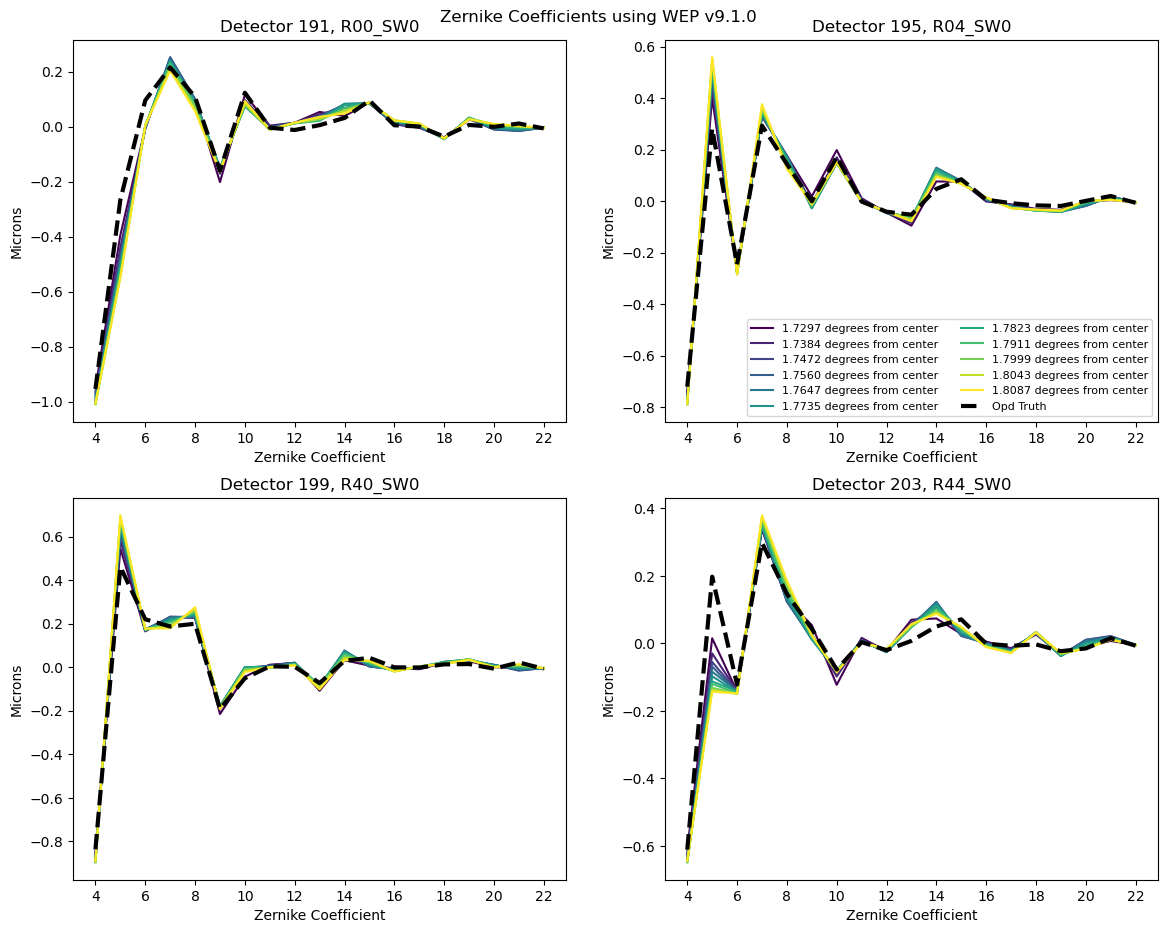

In [28]:
# Show zernikes on each sensor across different vignetting
i = 1
iter_num = 0
fig = plt.figure(figsize=(14, 10))

n = len(distToCenterVals[:11])
colors = plt.cm.viridis(np.linspace(0,1,n))

for extraId in extraDetectorIds:
    fig.add_subplot(2, 2, i)
    for j in range(11):
        plt.plot(np.arange(4, 23), iterZernsDanish[iter_num][f'{extraId}_wep'][j], label=f'{distToCenterVals[j]:.4f} degrees from center', c=colors[j])
    plt.plot(np.arange(4, 23), iterZernsDanish[iter_num][f'{extraId}_opd'][j]/1e3, '--', label=f'Opd Truth', lw=3, c='k')
    if i == 2:
        plt.legend(loc=4, ncol=2, fontsize=8)
    plt.title(f'Detector {extraId}, {camera[extraId].getName()}')
    plt.ylabel('Microns')
    plt.xlabel('Zernike Coefficient')
    plt.xticks(np.arange(4, 23, 2))
    i+=1
plt.suptitle('Zernike Coefficients using WEP v9.1.0')
plt.subplots_adjust(top=0.95)

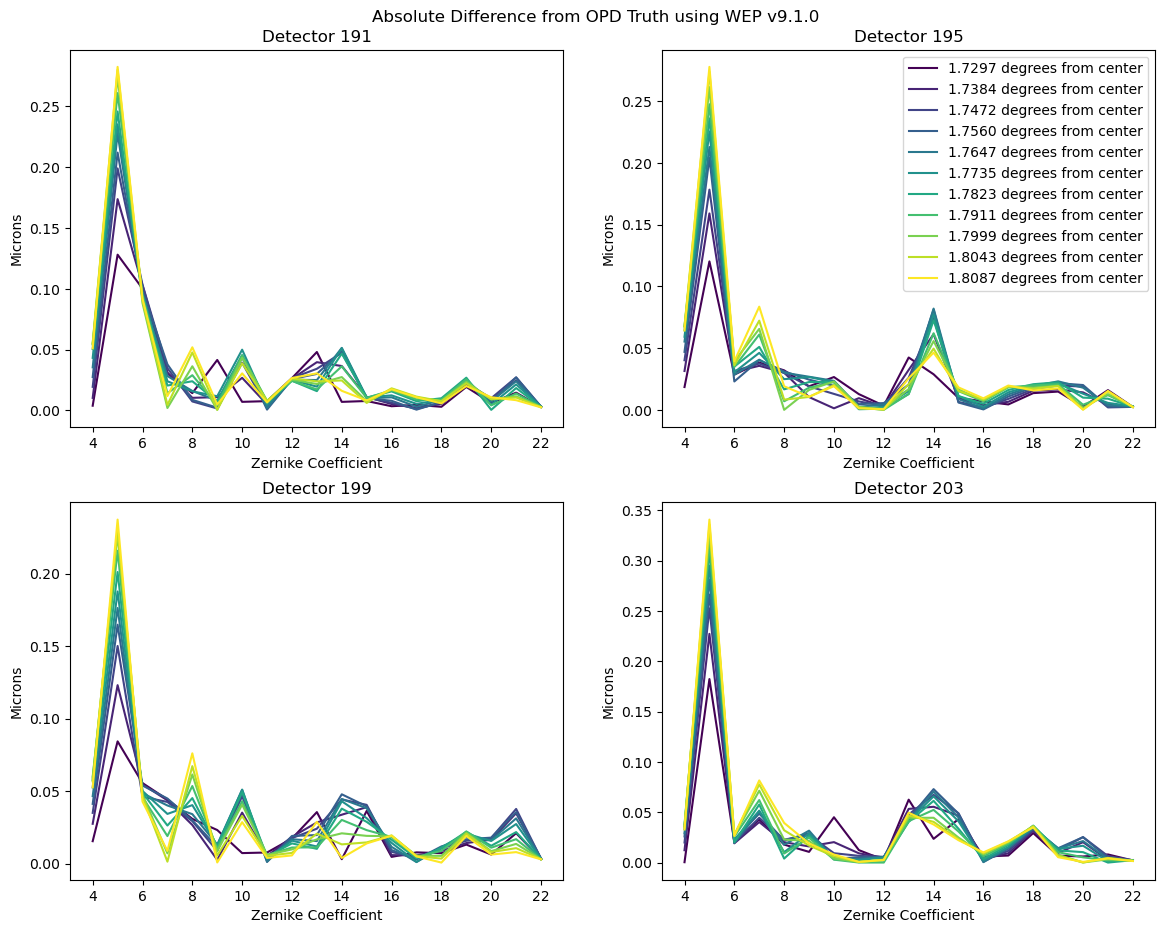

In [29]:
# Show zernikes on each sensor across different vignetting
i = 1
iter_num = 0
fig = plt.figure(figsize=(14, 10))
for extraId in extraDetectorIds:
    fig.add_subplot(2, 2, i)
    for j in range(11):
        plt.plot(
            np.arange(4, 23), 
            np.abs(iterZernsDanish[iter_num][f'{extraId}_wep'][j]-iterZernsDanish[iter_num][f'{extraId}_opd'][j]/1e3), 
            label=f'{distToCenterVals[j]:.4f} degrees from center',
            c=colors[j]
        )
        plt.xticks(np.arange(4, 23, 2))
    if i == 2:
        plt.legend()
    plt.title(f'Detector {extraId}')
    plt.ylabel('Microns')
    plt.xlabel('Zernike Coefficient')
    i+=1
plt.suptitle('Absolute Difference from OPD Truth using WEP v9.1.0')
plt.subplots_adjust(top=0.94)

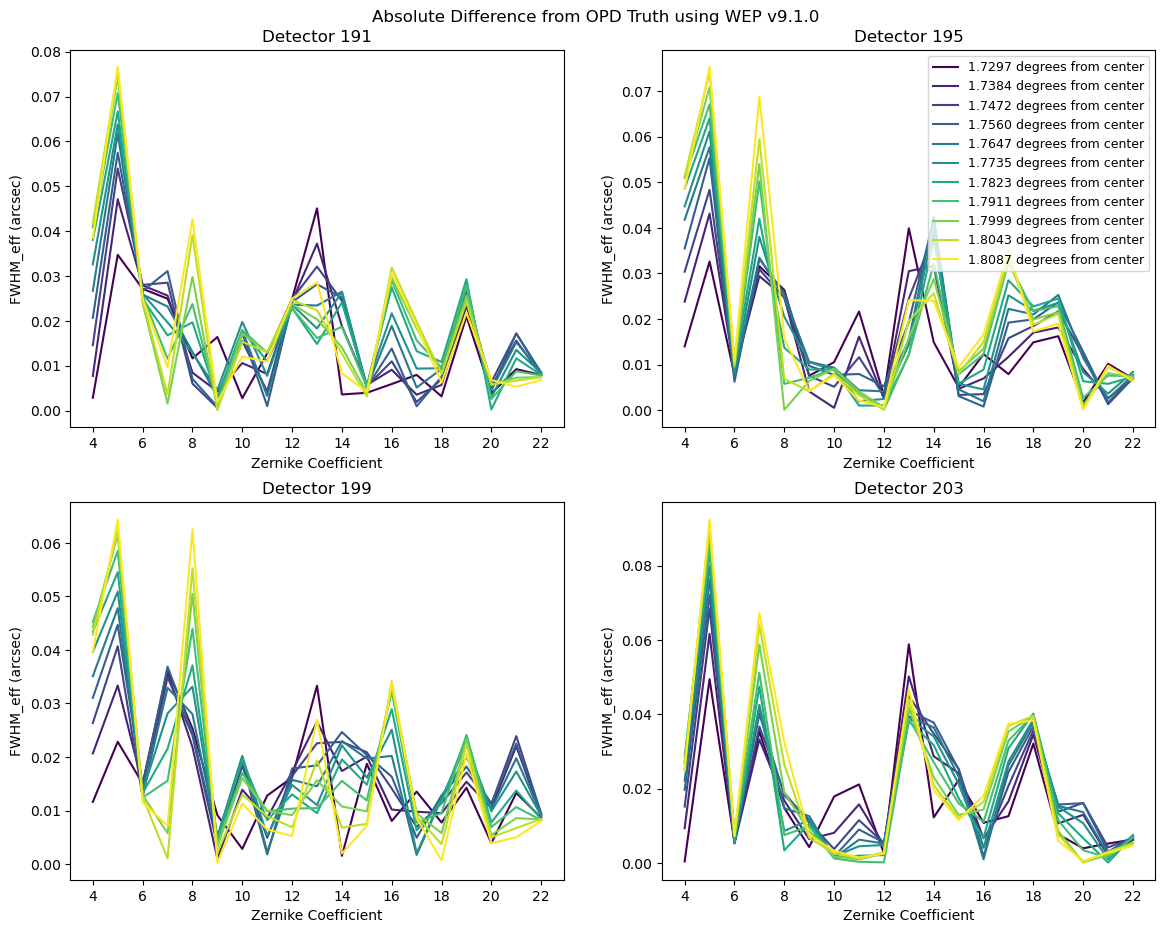

In [30]:
# Show zernikes on each sensor across different vignetting
i = 1
iter_num = 0
fig = plt.figure(figsize=(14, 10))
for extraId in extraDetectorIds:
    fig.add_subplot(2, 2, i)
    for j in range(11):
        plt.plot(
            np.arange(4, 23), 
            convertZernikesToPsfWidth(np.abs(iterZernsDanish[iter_num][f'{extraId}_wep'][j]-iterZernsDanish[iter_num][f'{extraId}_opd'][j]/1e3)), 
            label=f'{distToCenterVals[j]:.4f} degrees from center', 
            c=colors[j]
        )
        plt.xticks(np.arange(4, 23, 2))
    if i == 2:
        plt.legend(fontsize=9)
    plt.title(f'Detector {extraId}')
    plt.ylabel('FWHM_eff (arcsec)')
    plt.xlabel('Zernike Coefficient')
    i+=1
plt.suptitle('Absolute Difference from OPD Truth using WEP v9.1.0')
plt.subplots_adjust(top=0.94)

The `danish` results show good agreement across the range of distances from the center of the focal plane up to 1.81 degrees. `danish` also shows a clear trend in some Zernikes (Z4, Z7, Z8) of increasing errors as vignetting increases. Overall, the maximum errors in microns are comparable to the TIE plots above. Below we compare the mean results of the two methods.

Text(0.5, 0, 'Zernike Coefficient')

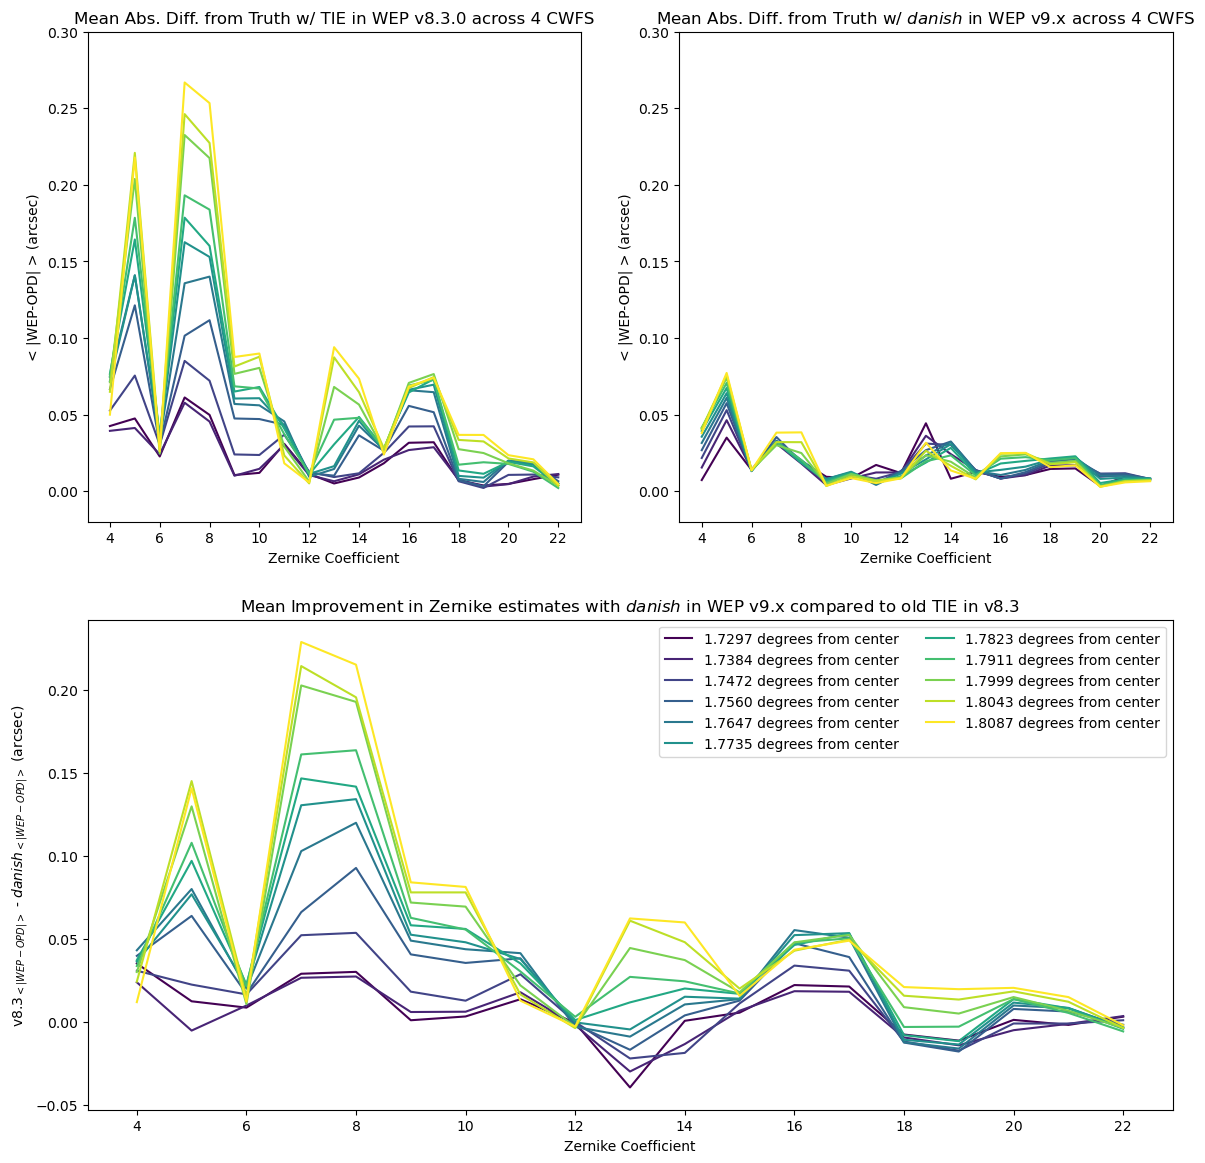

In [31]:
# Show zernikes on each sensor across different vignetting
i = 1
iter_num = 0
fig = plt.figure(figsize=(14, 14))
fig.add_subplot(2,2,2)
for j in range(11):
    diff = np.zeros(19)
    for extraId in extraDetectorIds:
        diff += np.abs(iterZernsDanish[iter_num][f'{extraId}_wep'][j]-iterZernsDanish[iter_num][f'{extraId}_opd'][j]/1e3)
    plt.plot(
        np.arange(4, 23),
        convertZernikesToPsfWidth(diff / 4),
        label=f'{distToCenterVals[j]:.4f} degrees from center',
        c=colors[j]
    )
plt.xticks(np.arange(4, 23, 2))
plt.ylim(-0.02, 0.30)
plt.ylabel('< |WEP-OPD| > (arcsec)')
plt.xlabel('Zernike Coefficient')
#plt.legend()
plt.title('Mean Abs. Diff. from Truth w/ $danish$ in WEP v9.x across 4 CWFS')

fig.add_subplot(2,2,1)
for j in range(11):
    diff = np.zeros(19)
    for extraId in extraDetectorIds:
        diff += np.abs(iterZernsOldTie[iter_num][f'{extraId}_wep'][j]-iterZernsOldTie[iter_num][f'{extraId}_opd'][j]/1e3)
    plt.plot(
        np.arange(4, 23),
        convertZernikesToPsfWidth(diff / 4),
        label=f'{distToCenterVals[j]:.4f} degrees from center',
        c=colors[j]
    )
plt.xticks(np.arange(4, 23, 2))
plt.ylim(-0.02, 0.30)
plt.ylabel('< |WEP-OPD| > (arcsec)')
plt.xlabel('Zernike Coefficient')
#plt.legend()
plt.title('Mean Abs. Diff. from Truth w/ TIE in WEP v8.3.0 across 4 CWFS')

fig.add_subplot(2, 1, 2)
for j in range(11):
    diff = np.zeros(19)
    for extraId in extraDetectorIds:
        diff += np.abs(iterZernsOldTie[iter_num][f'{extraId}_wep'][j]-iterZernsOldTie[iter_num][f'{extraId}_opd'][j]/1e3) - \
        np.abs(iterZernsDanish[iter_num][f'{extraId}_wep'][j]-iterZernsDanish[iter_num][f'{extraId}_opd'][j]/1e3)
    plt.plot(
        np.arange(4, 23),
        convertZernikesToPsfWidth(diff / 4),
        label=f'{distToCenterVals[j]:.4f} degrees from center',
        c=colors[j]
    )
plt.xticks(np.arange(4, 23, 2))

plt.legend(ncol=2)
plt.title('Mean Improvement in Zernike estimates with $danish$ in WEP v9.x compared to old TIE in v8.3')
plt.ylabel('v8.3$_{<|WEP-OPD|>}$ - $danish_{<|WEP-OPD|>}$ (arcsec)')
plt.xlabel('Zernike Coefficient')

The figure above compares the old TIE to `danish` and shows consistent overall improvement by up to 0.2 arcseconds in Zernikes 7 and 8 at the most vignetted donuts that `danish` can measure.

Text(0.5, 0, 'Zernike Coefficient')

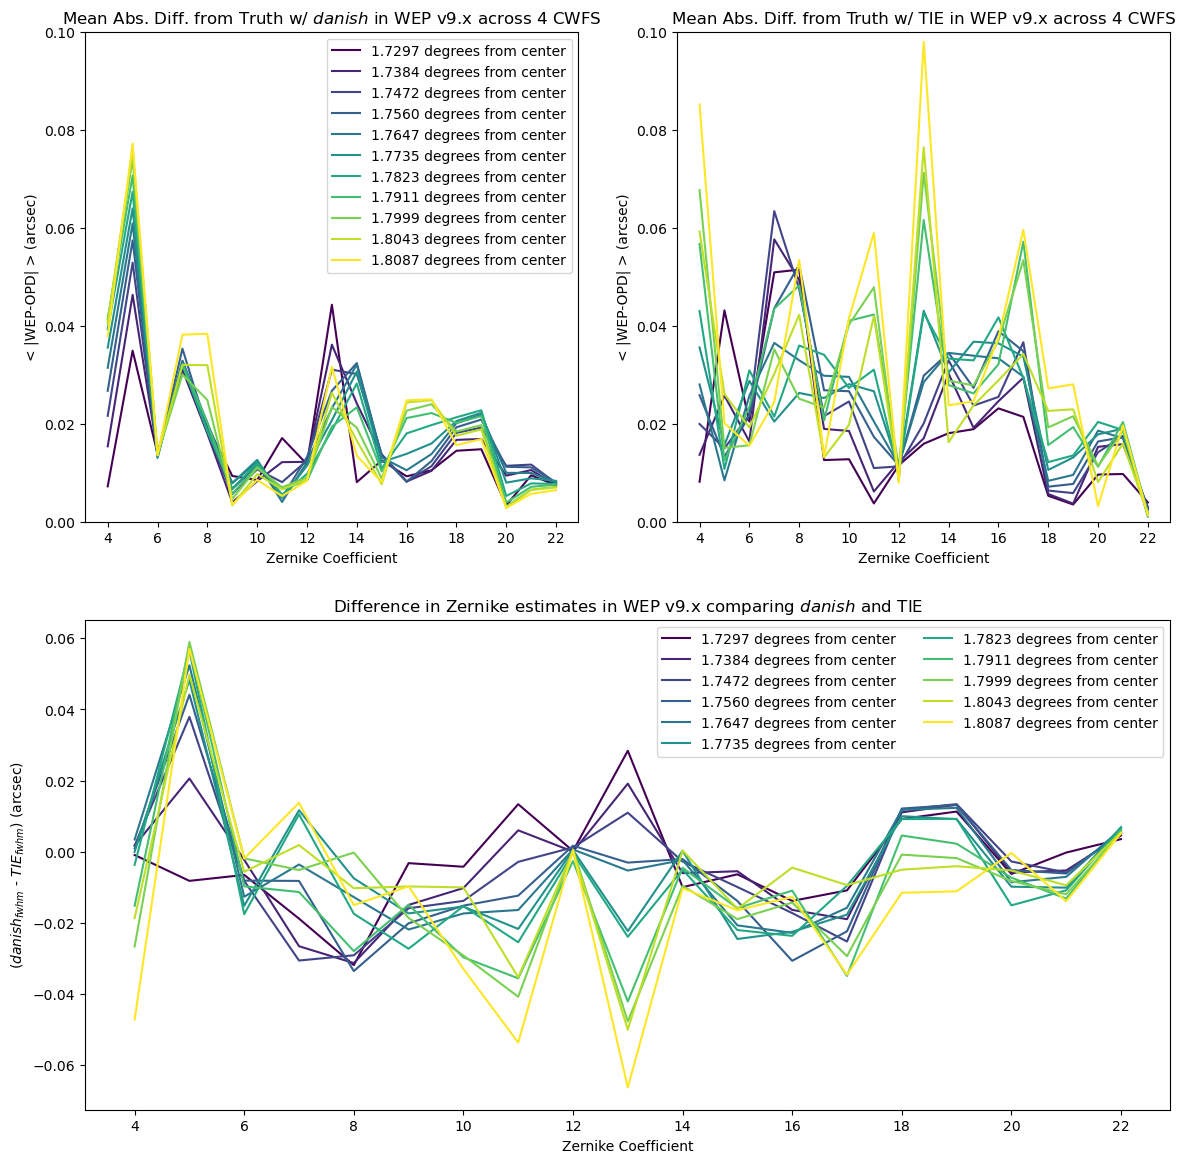

In [32]:
# Show zernikes on each sensor across different vignetting
i = 1
iter_num = 0
fig = plt.figure(figsize=(14, 14))
fig.add_subplot(2,2,2)
for j in range(11):
    diff = np.zeros(19)
    for extraId in extraDetectorIds:
        diff += np.abs(iterZerns[iter_num][f'{extraId}_wep'][j]-iterZerns[iter_num][f'{extraId}_opd'][j]/1e3)
    plt.plot(
        np.arange(4, 23),
        convertZernikesToPsfWidth(diff / 4),
        label=f'{distToCenterVals[j]:.4f} degrees from center',
        c=colors[j]
    )
plt.xticks(np.arange(4, 23, 2))
plt.ylim(-0.00, 0.1)
plt.ylabel('< |WEP-OPD| > (arcsec)')
plt.xlabel('Zernike Coefficient')
# plt.legend()
plt.title('Mean Abs. Diff. from Truth w/ TIE in WEP v9.x across 4 CWFS')

fig.add_subplot(2,2,1)
for j in range(11):
    diff = np.zeros(19)
    for extraId in extraDetectorIds:
        diff += np.abs(iterZernsDanish[iter_num][f'{extraId}_wep'][j]-iterZernsDanish[iter_num][f'{extraId}_opd'][j]/1e3)
    plt.plot(
        np.arange(4, 23),
        convertZernikesToPsfWidth(diff / 4),
        label=f'{distToCenterVals[j]:.4f} degrees from center',
        c=colors[j]
    )
plt.xticks(np.arange(4, 23, 2))
plt.ylim(-0.00, 0.1)
plt.ylabel('< |WEP-OPD| > (arcsec)')
plt.xlabel('Zernike Coefficient')
plt.legend()
plt.title('Mean Abs. Diff. from Truth w/ $danish$ in WEP v9.x across 4 CWFS')

fig.add_subplot(2, 1, 2)
for j in range(11):
    diff = np.zeros(19)
    for extraId in extraDetectorIds:
        diff += np.abs(iterZernsDanish[iter_num][f'{extraId}_wep'][j]-iterZernsDanish[iter_num][f'{extraId}_opd'][j]/1e3) - \
        np.abs(iterZerns[iter_num][f'{extraId}_wep'][j]-iterZerns[iter_num][f'{extraId}_opd'][j]/1e3)
    plt.plot(
        np.arange(4, 23),
        convertZernikesToPsfWidth(diff / 4),
        label=f'{distToCenterVals[j]:.4f} degrees from center',
        c=colors[j]
    )
plt.xticks(np.arange(4, 23, 2))

plt.legend(ncol=2)
plt.title('Difference in Zernike estimates in WEP v9.x comparing $danish$ and TIE')
plt.ylabel('($danish_{fwhm}$ - $TIE_{fwhm}$) (arcsec)')
plt.xlabel('Zernike Coefficient')

This last figure shows a comparison of `danish` and the new TIE code and demonstrates that the new TIE and `danish` perform similarly across the vignetted donuts up to 1.8087 degrees from the center of the focal plane. The difference between the two methods is never more than ~0.06 arcseconds for a single zernike.

With both the new TIE and `danish` showing improvement over the old TIE code, the question we next need to answer is how much vignetting can we accept before our ability to correct the wavefront is noticeably compromised?

## Closed loop results with vignetting <a id='closed_loop'></a>

To answer this question we look in this section at the convergence of the AOS closed loop across a series of closed loop simulations where a single donut pair is used for each 10-iteration closed loop test. In each simulation the extra-focal donut remains the same but the paired intra-focal donut is simulated at a different distance from the center of the focal plane in each test. 

Using convergence of the closed loop as the determining factor we will try to define a limit for acceptable donuts based upon their distance from the center of the focal plane. In this section we look at the performance of the closed loop with varying amounts of vignetting.

### New TIE with background, `g_mag` = 14.0

In our tests all the stars are set to `g_mag` = 14.0 and we include sky background and atmospheric effects in the `imSim` simulations. We use the closed loop command and catalogs highlighted at the beginning of the notebook in the [Logistics](#Logistics) section.

In [33]:
field_distances = []
for dir_name in os.listdir(supporting_data_folder):
    if dir_name == 'catalogs':
        continue
    field_dist = dir_name.split('_')[2]
    if field_dist == 'all':
        continue
    field_distances.append(field_dist)
field_distances.sort()

In [34]:
PSSN_vals = {}
FWHM_vals = {}
for field_dist in field_distances:
    loop_PSSN = []
    for loop_iter in range(10):
        # PSSN files contain PSSN values and FWHM values for each iteration
        loop_PSSN.append(np.genfromtxt(os.path.join(f'{supporting_data_folder}/single_donut_{field_dist}/iter{loop_iter}/img/PSSN.txt')))
    PSSN_vals[field_dist] = np.array(loop_PSSN)[:, 0]
    FWHM_vals[field_dist] = np.array(loop_PSSN)[:, 1]

(0.15, 0.42)

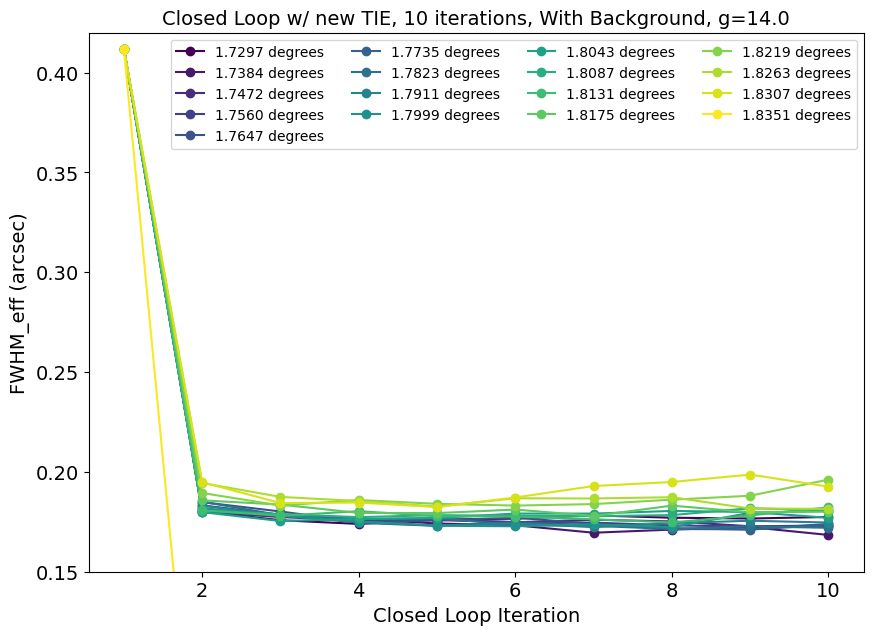

In [35]:
fig = plt.figure(figsize=(10, 7))

n = len(field_distances)
colors = plt.cm.viridis(np.linspace(0,1,n))

for idx, field_dist in enumerate(field_distances):
    plt.plot(
        np.arange(1, 11),
        FWHM_vals[field_dist][:, 4], 
        '-o', 
        label=f"{field_dist} degrees",
        c=colors[idx]
    )
plt.legend(fontsize=10, ncol=4)
plt.xlabel('Closed Loop Iteration', size=14)
plt.ylabel('FWHM_eff (arcsec)', size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.title('Closed Loop w/ new TIE, 10 iterations, With Background, g=14.0', size=14)
plt.ylim(0.15, 0.42)

We see that the closed loop reaches convergence until we reach 1.8351 degrees from the center of the focal plane. At this point the vignetting reaches the center of the donut and breaks the TIE. This is the limit of applicability but let's look closer and see at which point the FWHM of the images actually begins to deteriorate when using vignetted donuts.

To get a better picture of the convergence values let's omit the first iteration with the initial, large perturbations and zoom in on iterations 2-10.

Text(0.5, 1.0, 'Closed Loop w/ new TIE, Iterations 2-10, With Background, g=14.0')

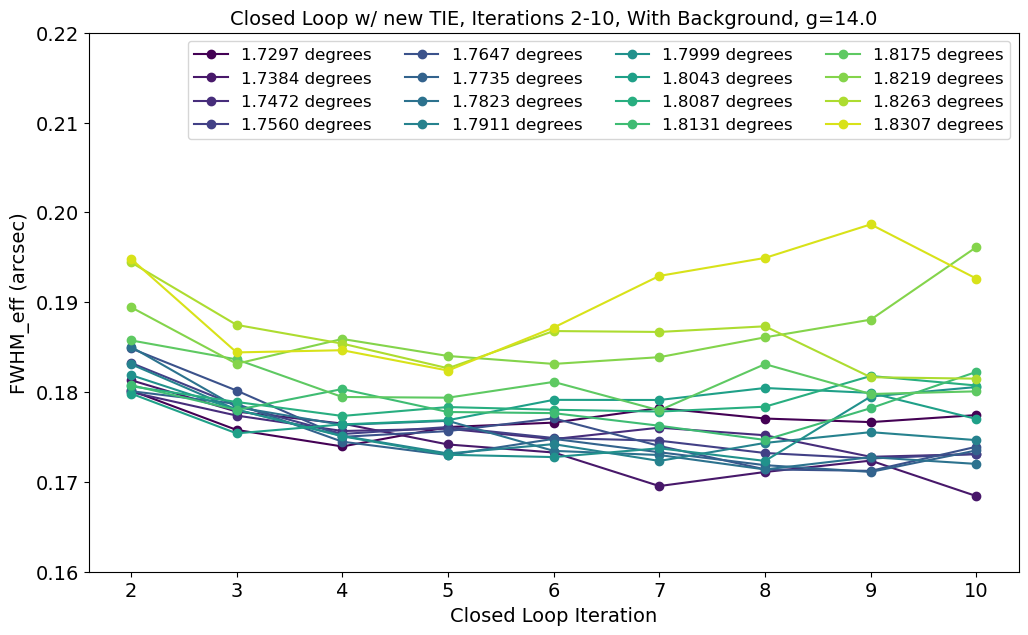

In [36]:
fig = plt.figure(figsize=(12, 7))
for idx, field_dist in enumerate(field_distances[:-1]):
    plt.plot(
        np.arange(2, 11),
        FWHM_vals[field_dist][1:, 4], 
        '-o', 
        label=f"{field_dist} degrees",
        c=colors[idx]
    )
plt.legend(fontsize=12, ncol=4)
plt.xlabel('Closed Loop Iteration', size=14)
plt.ylabel('FWHM_eff (arcsec)', size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.ylim((0.16, 0.22))
plt.title('Closed Loop w/ new TIE, Iterations 2-10, With Background, g=14.0', size=14)

There seems to be a level of FWHM around 0.18 arcseconds where the convergence is steady as the intra-focal donut is simulated. But as the location of the intra-focal donut goes beyond 1.8175 degrees from the center of the focal plane the final FWHM value of convergence starts to deteriorate. Let's cut out all values greater than that and look at how the plot looks.

Text(0.5, 1.0, 'Closed Loop w/ new TIE, Iterations 2-10, With Background, g=14.0')

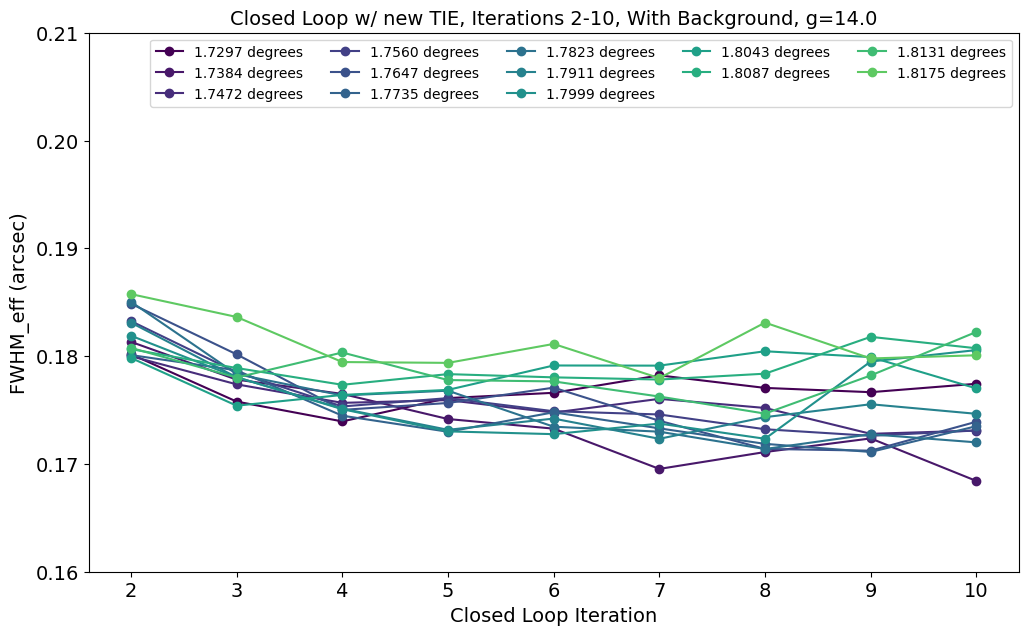

In [37]:
fig = plt.figure(figsize=(12, 7))

for idx, field_dist in enumerate(field_distances[:13]):
    plt.plot(
        np.arange(2, 11),
        FWHM_vals[field_dist][1:, 4], 
        '-o', 
        label=f"{field_dist} degrees",
        c=colors[idx]
    )
plt.legend(fontsize=10, ncol=5)
plt.xlabel('Closed Loop Iteration', size=14)
plt.ylabel('FWHM_eff (arcsec)', size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.ylim((0.16, 0.21))
plt.title('Closed Loop w/ new TIE, Iterations 2-10, With Background, g=14.0', size=14)

In the final plot we see that we reach a consistent value for the converged FWHM of the images when using donuts up to 1.8175 degrees from the center of the focal plane.

Keep in mind that this 1.8175 is beyond the range of applicability we have found with `danish` and so it would be good to check the convergence performance of `danish` in the closed loop before making a final decision. In the next section we look at the `danish` results.

### `danish` with background, `g_mag` = 14.0

In our tests all the stars are set to `g_mag` = 14.0 and we include sky background and atmospheric effects in the `imSim` simulations. We use the closed loop command and catalogs highlighted at the beginning of the notebook in the [Logistics](#Logistics) section.

In [38]:
PSSN_vals_danish = {}
FWHM_vals_danish = {}
for field_dist in field_distances:
    loop_PSSN = []
    for loop_iter in range(10):
        # PSSN files contain PSSN values and FWHM values for each iteration
        loop_PSSN.append(np.genfromtxt(os.path.join(f'{danish_supporting_data_folder}/single_donut_{field_dist}/iter{loop_iter}/img/PSSN.txt')))
    PSSN_vals_danish[field_dist] = np.array(loop_PSSN)[:, 0]
    FWHM_vals_danish[field_dist] = np.array(loop_PSSN)[:, 1]

(0.15, 0.42)

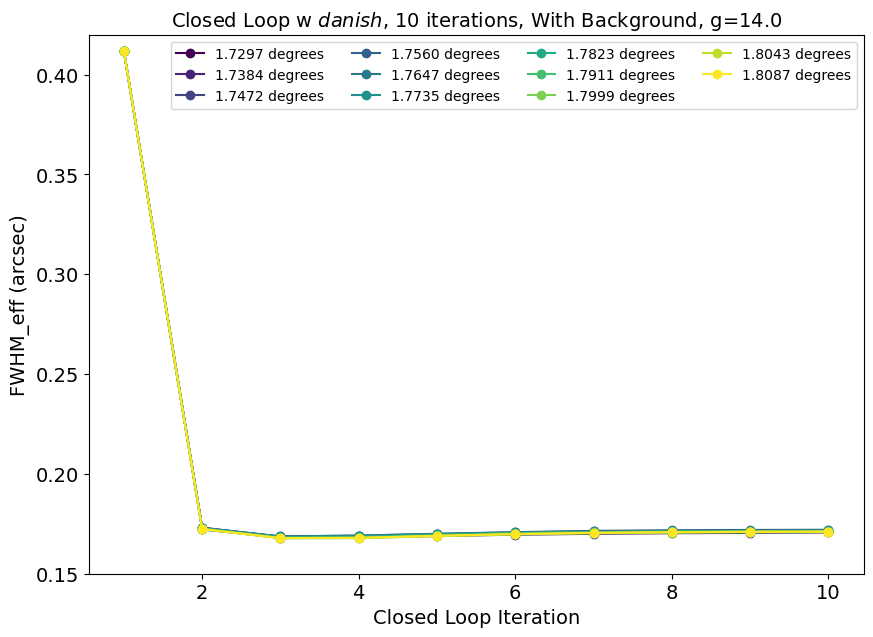

In [39]:
fig = plt.figure(figsize=(10, 7))

n = len(field_distances[:11])
colors = plt.cm.viridis(np.linspace(0,1,n))

for idx, field_dist in enumerate(field_distances[:11]):
    plt.plot(
        np.arange(1, 11),
        FWHM_vals_danish[field_dist][:, 4], 
        '-o', 
        label=f"{field_dist} degrees",
        c=colors[idx]
    )
plt.legend(fontsize=10, ncol=4)
plt.xlabel('Closed Loop Iteration', size=14)
plt.ylabel('FWHM_eff (arcsec)', size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.title('Closed Loop w $danish$, 10 iterations, With Background, g=14.0', size=14)
plt.ylim(0.15, 0.42)

We see that the closed loop converges almost identically up to the limit of 1.8087 degrees from the center of the focal plane at which point `danish` fails. Let's look closer and see if there are actually any small differences in the convergence of the closed loop as we zoom in on iterations 2-10.

Text(0.5, 1.0, 'Closed Loop w/ $danish$, Iterations 2-10, With Background, g=14.0')

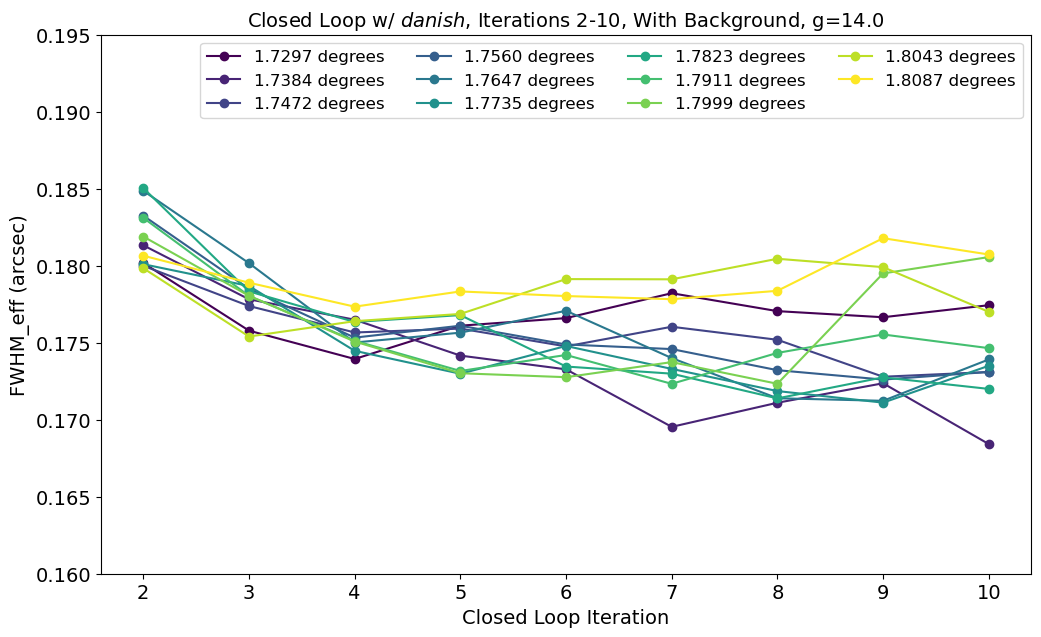

In [40]:
fig = plt.figure(figsize=(12, 7))
for idx, field_dist in enumerate(field_distances[:11]):
    plt.plot(
        np.arange(2, 11),
        FWHM_vals[field_dist][1:, 4], 
        '-o', 
        label=f"{field_dist} degrees",
        c=colors[idx]
    )
plt.legend(fontsize=12, ncol=4)
plt.xlabel('Closed Loop Iteration', size=14)
plt.ylabel('FWHM_eff (arcsec)', size=14)
plt.xticks(size=14)
plt.yticks(size=14)
plt.ylim((0.16, 0.195))
plt.title('Closed Loop w/ $danish$, Iterations 2-10, With Background, g=14.0', size=14)

There seems to be a level of FWHM between 0.17 and 0.18 arcseconds where the convergence is steady across the range of intra-focal donuts tested. There are small differences but the values overall are quite consistent.

### Summary

The new TIE code and `danish` both perform about the same in the closed loop reaching convergence at a level between 0.17 and 0.18 arcseconds but `danish` does have less scatter at difference distance from the focal plane center. Based upon the performance of the new TIE code and `danish` in the closed loop tests it seems that if we set our field distance limit for WEP donuts to be 1.808 degrees from the center of the focal plane we will be able to reach convergence in the closed loop for both the TIE method and `danish`. In a related PR on `ts_wep` we will adjust the default limit to this new value from the existing 1.813 degrees.

In the next section we calculate exactly how much of the intra-focal detector we will lose with this new value.



## Calculate area of detector cut off <a id='detector'></a>

Here we will calculate the distance each pixel in the intra-focal detector is from the center of the field and then calculate how many pixels are beyond the limit we will set for the AOS baseline pipeline at 1.813 degrees.

In [41]:
intraIm = butler.get('postISRCCD', dataId=intraDataIds[str(192)], collections=['ts_imsim_1000'])

In [42]:
# Create meshgrid for contours and calculate distance to center for points in grid
import lsst.geom
from lsst.afw.cameraGeom import PIXELS, FIELD_ANGLE

X, Y = np.meshgrid(np.arange(0, 4096, 5), np.arange(0, 2001, 5))
Z = np.zeros(np.shape(X))

for x_idx in np.arange(0, 4096, 5):
    for y_idx in np.arange(0, 2001, 5):
        # Use detector object to convert between Pixels and Field Angle
        field_xy = intraIm.getDetector().transform(
            lsst.geom.Point2D(x_idx, y_idx), PIXELS, FIELD_ANGLE
        )
        field_dist = np.sqrt(field_xy[0]**2 + field_xy[1]**2)
        Z[int(y_idx/5), int(x_idx/5)] = np.degrees(field_dist)


Text(0, 0.5, 'Y Pixels')

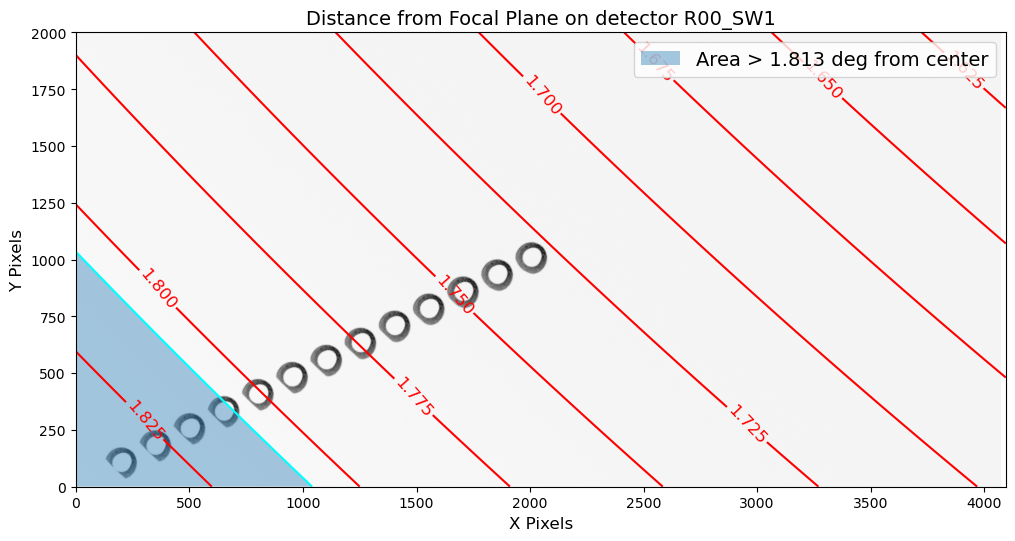

In [43]:
fig = plt.figure(figsize=(12, 7))
ax = plt.gca()
plt.imshow(intraIm.getImage().getArray(), cmap=plt.get_cmap('Greys'))
C = plt.contour(X, Y, Z, colors='red', levels=np.arange(1.60, 1.91, 0.025))
C1 = plt.contour(X, Y, Z, colors='cyan', levels=[1.808])
ax.clabel(C, inline=True, fontsize=12)
ax.fill_between(C1.allsegs[0][0][:,0], C1.allsegs[0][0][:,1], np.zeros(len(C1.allsegs[0][0])), alpha=0.4, label='Area > 1.813 deg from center')
plt.title(f'Distance from Focal Plane on detector {intraIm.getDetector().getName()}', size=14)
plt.legend(fontsize=14)
plt.xlabel('X Pixels', size=12)
plt.ylabel('Y Pixels', size=12)


In [44]:
frac_cutoff = len(np.where(Z > 1.808)[0])/(np.shape(Z)[0]*np.shape(Z)[1])

In [45]:
print(f"The amount of the detector cutoff is {frac_cutoff*100:.4f} percent for detector {intraIm.getDetector().getName()}.")

The amount of the detector cutoff is 6.5142 percent for detector R00_SW1.


Setting the limit of sources used in our baseline AOS pipeline still leaves us ~93.5% of the detector area. This seems acceptable and it does not look like we need to look at further vignetting algorithms but should focus our efforts on deblending to make sure we make the best use of the remaining 93.5% of the detector to get sources.

On the full focal plane this will affect some science detectors on the edge of the focal plane (~32 out of 189). In some cases this cutoff will affect these science detectors to a greater extent than the wavefront detectors. Looking at the plot below it seems that when running full focal plane tests it would be good to take note of this and avoid detectors such as `R43_S22` which has most of its observable area beyond our 1.808 degree limit for WEP.

Text(0, 0.5, 'Degrees')

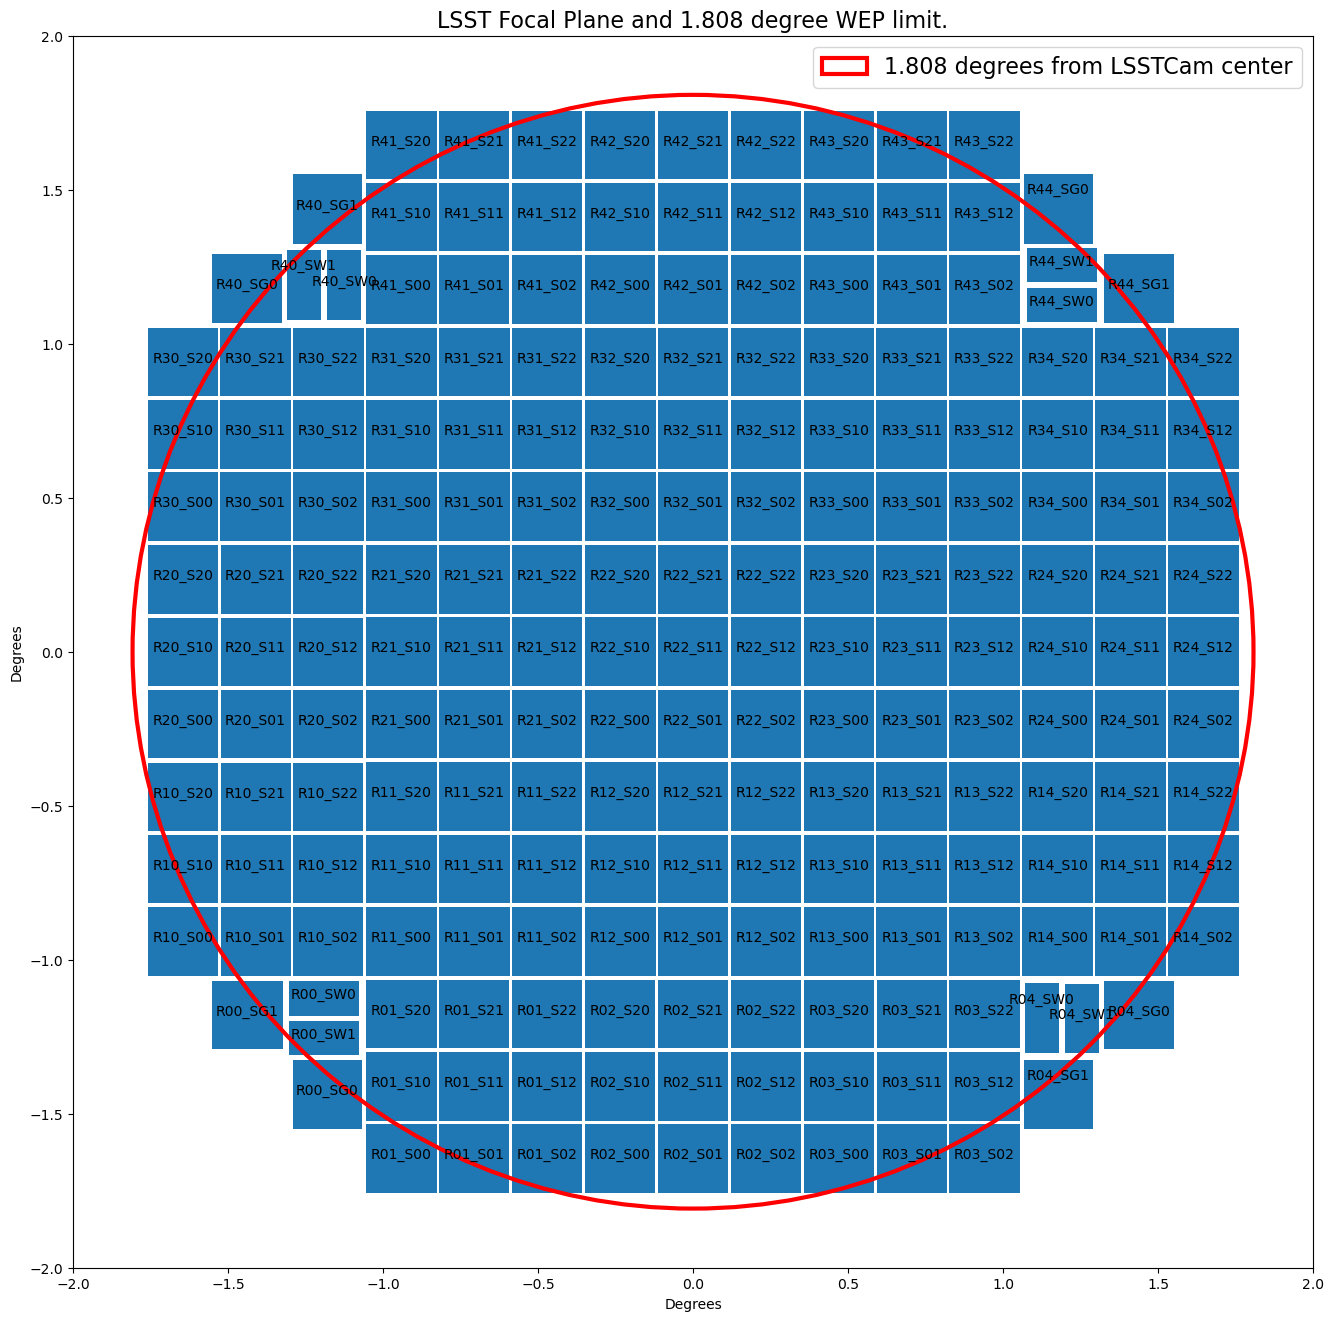

In [46]:
from matplotlib.patches import Rectangle, Circle
fig = plt.figure(figsize=(16,16))
for detector in camera:
    corners = detector.getCorners(FIELD_ANGLE)
    center = detector.getCenter(FIELD_ANGLE)
    centerX = np.degrees(center[0])
    centerY = np.degrees(center[1])
   
    ax = plt.gca()
    bbox = detector.getBBox()
    det_id = detector.getId()
    if det_id < 189:
        rect = Rectangle(np.degrees(corners[0]), bbox.getWidth()/5/3600, bbox.getHeight()/5/3600)
        plt.text(centerX, centerY, f'{detector.getName()}', ha='center')
    else:
        n_quarter = detector.getOrientation().getNQuarter()
        if n_quarter % 4 == 0:
            rect = Rectangle(np.degrees(corners[0]), bbox.getWidth()/5/3600, bbox.getHeight()/5/3600)
            plt.text(centerX, centerY, f'{detector.getName()}', ha='center')
        elif n_quarter % 4 == 1:
            rect = Rectangle(np.degrees(corners[3]), bbox.getHeight()/5/3600, bbox.getWidth()/5/3600)
            plt.text(centerX, centerY, f'{detector.getName()}', ha='center')
        elif n_quarter % 4 == 2:
            rect = Rectangle(np.degrees(corners[2]), bbox.getWidth()/5/3600, bbox.getHeight()/5/3600)
            plt.text(centerX, centerY, f'{detector.getName()}', ha='center')
        elif n_quarter % 4 == 3:
            plt.text(centerX, centerY+.05, f'{detector.getName()}', ha='center')
            rect = Rectangle(np.degrees(corners[1]), bbox.getHeight()/5/3600, bbox.getWidth()/5/3600)
    ax.add_patch(rect)

circle = Circle((0.0, 0.0), radius=1.808, fill=False, label='1.808 degrees from LSSTCam center', color='r', lw=3)
ax.add_patch(circle)
    
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.legend(fontsize=16)
plt.title('LSST Focal Plane and 1.808 degree WEP limit.', size=16)
plt.xlabel('Degrees')
plt.ylabel('Degrees')

This 1.808 degree limit will be the default setting in the WEP pipeline as part of the DonutSelectorTask under the `maxFieldDist` configuration parameter ([code](https://github.com/lsst-ts/ts_wep/blob/e1c9b0489b2b4705771237b376aabedf6c46d515/python/lsst/ts/wep/task/donutSourceSelectorTask.py#L65-L69)). To set this to a different parameter when running the pipeline with a yaml configuration file this setting can be set like this:
```yaml
generateDonutCatalogWcsTask :
  class: lsst.ts.wep.task.generateDonutCatalogWcsTask.GenerateDonutCatalogWcsTask
  config:
   donutSelector.maxFieldDist: 1.765 # Maximum distance from center of focal plane in degrees.
```